In [ ]:
# Cell 1: Install Dependencies
!pip install GDAL scikit-learn numpy scipy matplotlib seaborn pandas

In [ ]:
# Cell 2: Core Classes and Auxiliary Functions
import numpy as np
from numpy import ma
from osgeo import gdal, osr
import scipy.ndimage as ndi
import pandas as pd
from numpy.lib.stride_tricks import as_strided
from scipy.ndimage import distance_transform_edt
import pickle
import traceback

# ==============================================================================
# 1. UTILITIES AND DATA PROVIDER
# ==============================================================================
def get_gradations(arr):
    return np.unique(arr).tolist()

class Raster:
    """Clase adaptada para manejar datos ráster."""
    def __init__(self, filename=None):
        self.filename = filename
        self.bands = None
        self.bandcount = 0
        self.geodata = {}
        if filename: self._read()

    def geoDataMatch(self, other_raster):
        """Compara si la geometría de dos rásters coincide."""
        geodata1 = self.getGeodata()
        geodata2 = other_raster.getGeodata()
        if geodata1.get('xSize') != geodata2.get('xSize') or geodata1.get('ySize') != geodata2.get('ySize'):
            print(f"ERROR: Las dimensiones no coinciden. {self.filename.split('/')[-1]} ({geodata1.get('xSize')}x{geodata1.get('ySize')}) vs {other_raster.filename.split('/')[-1]} ({geodata2.get('xSize')}x{geodata2.get('ySize')})")
            return False
        t1 = geodata1.get('transform')
        t2 = geodata2.get('transform')
        if not np.allclose(t1, t2, atol=1e-6):
            print(f"ERROR: La geotransformación no coincide. {self.filename.split('/')[-1]} vs {other_raster.filename.split('/')[-1]}")
            return False
        return True

    def _read(self):
        data = gdal.Open(self.filename)
        self.geodata['xSize'], self.geodata['ySize'] = data.RasterXSize, data.RasterYSize
        self.geodata['proj'], self.geodata['transform'] = data.GetProjection(), data.GetGeoTransform()
        self.bandcount = data.RasterCount
        self.bands = []
        for i in range(1, self.bandcount + 1):
            band = data.GetRasterBand(i)
            nodata = band.GetNoDataValue()
            arr = band.ReadAsArray()
            mask = (arr == nodata) if nodata is not None else np.zeros_like(arr, dtype=bool)
            self.bands.append(ma.array(arr, mask=mask))

    def create(self, bands_list, geodata):
        self.bands = [ma.array(b) for b in bands_list]
        self.bandcount = len(self.bands)
        self.geodata = geodata

    def getBand(self, bandNo): return self.bands[bandNo - 1]
    def getBandGradation(self, bandNo): return get_gradations(self.getBand(bandNo).compressed())
    def getGeodata(self): return self.geodata
    def getNeighbourhoodSize(self, ns): return (2 * ns + 1) ** 2

    def getNeighbours(self, row, col, ns, bandNo=1):
        band = self.getBand(bandNo)
        return band[row - ns : row + ns + 1, col - ns : col + ns + 1]

    def normalize(self, mode='mean'):
        for i in range(self.bandcount):
            band = self.bands[i]
            if mode == 'mean':
                mean, std = band.mean(), band.std()
                if std > 0: self.bands[i] = (band - mean) / std
            elif mode == 'maxmin':
                min_val, max_val = band.min(), band.max()
                if (max_val - min_val) > 0: self.bands[i] = (band - min_val) / (max_val - min_val)

    def save(self, filename):
        driver = gdal.GetDriverByName('GTiff')
        out_ds = driver.Create(filename, self.geodata['xSize'], self.geodata['ySize'], self.bandcount, gdal.GDT_Int16)
        out_ds.SetProjection(self.geodata['proj'])
        out_ds.SetGeoTransform(self.geodata['transform'])
        for i in range(self.bandcount):
            out_band = out_ds.GetRasterBand(i + 1)
            out_band.WriteArray(self.bands[i].filled(-9999))
            out_band.SetNoDataValue(-9999)
        out_ds.FlushCache()
        out_ds = None

# ==============================================================================
# 2. CÁLCULO DE MATRIZ DE TRANSICIÓN
# ==============================================================================
class CrossTable:
    def __init__(self, band1, band2, expand: bool = False):
        mask = band1.mask | band2.mask
        band1.mask, band2.mask = mask, mask
        self.X, self.Y = band1.compressed(), band2.compressed()
        self.graduation_x, self.graduation_y = get_gradations(self.X), get_gradations(self.Y)

        if expand:
            self.graduation_x = sorted(list(set(self.graduation_x + self.graduation_y)))
            self.graduation_y = self.graduation_x

        self.rows, self.cols = len(self.graduation_x), len(self.graduation_y)
        self._T = None

    def computeCrosstable(self):
        self._T = np.zeros([self.rows, self.cols], dtype=int)
        map_x = {val: i for i, val in enumerate(self.graduation_x)}
        map_y = {val: i for i, val in enumerate(self.graduation_y)}
        for i in range(len(self.X)):
            self._T[map_x.get(self.X[i])][map_y.get(self.Y[i])] += 1

    def getCrosstable(self):
        if self._T is None: self.computeCrosstable()
        return self._T

    def getTransition(self, fromClass, toClass):
        i, j = self.graduation_x.index(fromClass), self.graduation_y.index(toClass)
        return self.getCrosstable()[i, j]

    @property
    def n(self): return len(self.X)
    def getSumRows(self): return self.getCrosstable().sum(axis=1)
    def getSumCols(self): return self.getCrosstable().sum(axis=0)
    def getProbRows(self): return self.getSumRows() / self.n if self.n > 0 else np.array([])
    def getProbCols(self): return self.getSumCols() / self.n if self.n > 0 else np.array([])
    def getProbtable(self): return self.getCrosstable() / self.n if self.n > 0 else np.array([[]])

# ==============================================================================
# 3. MUESTREADOR DE DATOS
# ==============================================================================
class Sampler:
    def __init__(self, state_raster, factor_rasters, ns=1):
        self.state, self.factors, self.ns = state_raster, factor_rasters, ns
        self.data = None

    def _getSample(self, output_raster, row, col):
        factors_neighbors = []
        for i, factor in enumerate(self.factors):
            neighbors = factor.getNeighbours(row, col, self.ns)
            if neighbors.mask.any(): return None
            factors_neighbors.append(neighbors.flatten())

        state_neighbors = self.state.getNeighbours(row, col, self.ns)
        if state_neighbors.mask.any(): return None

        output_val = output_raster.getBand(1)[row, col]
        if ma.is_masked(output_val): return None

        return {'state': state_neighbors.flatten(), 'factors': np.hstack(factors_neighbors), 'output': output_val}

    def setTrainingData(self, output_raster, mode='Stratified', samples=5000):
        rows, cols = self.state.geodata['ySize'], self.state.geodata['xSize']
        collected_samples = []

        if mode == 'Random':
            while len(collected_samples) < samples:
                r, c = np.random.randint(self.ns, rows - self.ns), np.random.randint(self.ns, cols - self.ns)
                sample = self._getSample(output_raster, r, c)
                if sample: collected_samples.append(sample)

        elif mode == 'Stratified':
            categories = output_raster.getBandGradation(1)
            band = output_raster.getBand(1)
            if not categories:
                self.data = []
                return
            samples_per_cat = int(samples / len(categories)) if categories else 0

            for cat in categories:
                valid_pixels_mask = ~band.mask
                rows_cat, cols_cat = np.where((band.data == cat) & valid_pixels_mask)
                cat_indices = list(zip(rows_cat, cols_cat))

                if not cat_indices:
                    print(f"Advertencia: No se encontraron píxeles válidos para la Clase {cat} en el mapa final.")
                    continue

                count = 0
                while count < samples_per_cat:
                    if not cat_indices: break
                    idx = np.random.randint(len(cat_indices))
                    r, c = cat_indices.pop(idx)
                    if self.ns <= r < rows - self.ns and self.ns <= c < cols - self.ns:
                        sample = self._getSample(output_raster, r, c)
                        if sample:
                            collected_samples.append(sample)
                            count += 1

        np.random.shuffle(collected_samples)
        self.data = collected_samples

# ==============================================================================
# 4. PERCEPTRÓN MULTICAPA (MLP)
# ==============================================================================
class MLP:
    def __init__(self, *args):
        self.shape = args
        self.layers = [np.ones(s + 1) if i == 0 else np.ones(s) for i, s in enumerate(self.shape)]
        self.weights = [np.zeros((self.layers[i].size, self.layers[i + 1].size)) for i in range(len(self.shape) - 1)]
        self.dw = [0] * len(self.weights)
        self.reset()

    def reset(self):
        for i in range(len(self.weights)):
            Z = np.random.random(self.weights[i].shape)
            self.weights[i][...] = (2 * Z - 1) * 0.25

    def propagate_forward(self, data):
        self.layers[0][0:-1] = data
        for i in range(1, len(self.shape)):
            self.layers[i][...] = np.tanh(np.dot(self.layers[i - 1], self.weights[i - 1]))
        return self.layers[-1]

    def propagate_backward(self, target, lrate=0.01, momentum=0.01):
        deltas, error = [], target - self.layers[-1]
        deltas.append((1.0 - self.layers[-1]**2) * error)
        for i in range(len(self.shape) - 2, 0, -1):
            deltas.insert(0, np.dot(deltas[0], self.weights[i].T) * (1.0 - self.layers[i]**2))
        for i in range(len(self.weights)):
            layer, delta = np.atleast_2d(self.layers[i]), np.atleast_2d(deltas[i])
            dw = np.dot(layer.T, delta)
            self.weights[i] += lrate * dw + momentum * self.dw[i]
            self.dw[i] = dw

def mlp_batch_predict(input_batch, weights):
    """
    Realiza una propagación hacia adelante (predicción) para un lote completo de datos
    utilizando una lista de matrices de pesos ya entrenados.
    """
    current_activations = input_batch
    ones = np.ones((current_activations.shape[0], 1))
    input_with_bias = np.hstack([current_activations, ones])
    dot_product = np.dot(input_with_bias, weights[0])
    current_activations = np.tanh(dot_product)
    for weight_matrix in weights[1:]:
        dot_product = np.dot(current_activations, weight_matrix)
        current_activations = np.tanh(dot_product)
    return current_activations

# ==============================================================================
# 5. SIMULADOR UNIFICADO
# ==============================================================================
def sliding_window_view(arr, window_shape):
    """
    Crea una vista de ventana deslizante de un arreglo 2D.
    """
    s_row, s_col = arr.strides
    v_row, v_col = window_shape
    return as_strided(
        arr,
        shape=(arr.shape[0] - v_row + 1, arr.shape[1] - v_col + 1, v_row, v_col),
        strides=(s_row, s_col, s_row, s_col)
    )

class MlpSimulator:
    def __init__(self, initial_raster, factor_rasters, mlp_model, crosstable, ns=1, transition_priority=None):
        self.initial_raster = initial_raster
        self.factor_rasters = factor_rasters
        self.crosstable = crosstable
        self.ns = ns
        self.mlp_weights = mlp_model.weights
        self.transition_priority = transition_priority

    def run_simulation(self):
        rows, cols = self.initial_raster.geodata['ySize'], self.initial_raster.geodata['xSize']
        ns = self.ns
        window_size = 2 * ns + 1

        # --- Parte 1: Generación de Mapas de Potencial (Vectorizada) ---
        print("1/2: (Vectorizado) Preparando el lote de datos de entrada...")
        mascara_interior = ndi.binary_erosion(~self.initial_raster.getBand(1).mask, iterations=ns)
        initial_state_band = self.initial_raster.getBand(1).filled(0)
        state_windows = sliding_window_view(initial_state_band, (window_size, window_size))
        state_categories = self.crosstable.graduation_x
        num_state_classes = len(state_categories)
        one_hot_matrix = np.eye(num_state_classes, dtype=np.float32)
        max_cat_value = int(np.max(state_categories))
        mapper = np.zeros(max_cat_value + 1, dtype=int)
        for i, cat in enumerate(state_categories):
            mapper[int(cat)] = i
        mapped_indices = mapper[state_windows.astype(int)]
        state_dummy_windows = one_hot_matrix[mapped_indices, :-1]
        flat_state_input = state_dummy_windows.reshape(state_windows.shape[0], state_windows.shape[1], -1)
        all_factors_input = []
        for factor in self.factor_rasters:
            factor_band = factor.getBand(1).filled(0)
            factor_windows = sliding_window_view(factor_band, (window_size, window_size))
            flat_factor = factor_windows.reshape(factor_windows.shape[0], factor_windows.shape[1], -1)
            all_factors_input.append(flat_factor)
        padded_state = np.pad(flat_state_input, ((ns, ns), (ns, ns), (0, 0)), 'constant')
        input_list = [padded_state]
        for factor_input in all_factors_input:
            padded_factor = np.pad(factor_input, ((ns, ns), (ns, ns), (0, 0)), 'constant')
            input_list.append(padded_factor)
        full_input_map = np.concatenate(input_list, axis=2)
        input_batch = full_input_map[mascara_interior]
        print(f"   -> Procesando {len(input_batch)} píxeles en un solo lote.")
        print("   -> Ejecutando la predicción del MLP...")
        output_batch = mlp_batch_predict(input_batch, self.mlp_weights)
        potential_maps = {cat: np.zeros((rows, cols), dtype=np.float32) for cat in self.crosstable.graduation_y}
        output_categories = self.crosstable.graduation_y
        for i, cat in enumerate(output_categories):
            temp_map = np.zeros((rows, cols), dtype=np.float32)
            temp_map[mascara_interior] = output_batch[:, i]
            potential_maps[cat] = temp_map
        print("   -> Mapas de potencial generados.")

        # --- Parte 2: Asignación de Cambios ---
        new_state_map = self.initial_raster.getBand(1).copy()
        categories = self.crosstable.graduation_x
        print(f"2/2: Asignando cambios...")

        if self.transition_priority:
            print(" -> Usando orden de transición personalizado.")
            transitions = self.transition_priority
        else:
            print(" -> Usando orden de transición por defecto (automático).")
            transitions = []
            for initClass in categories:
                for finalClass in categories:
                    if initClass != finalClass:
                        transitions.append((initClass, finalClass))

        for initClass, finalClass in transitions:
            demand = self.crosstable.getTransition(initClass, finalClass)
            if demand == 0: continue
            candidate_pixels_mask = (self.initial_raster.getBand(1).data == initClass)
            suitability = potential_maps[finalClass] * candidate_pixels_mask
            suitability[~mascara_interior] = -np.inf
            suitability[new_state_map != initClass] = -np.inf
            num_candidates = np.sum(suitability > -np.inf)
            if num_candidates < demand: demand = num_candidates
            if demand > 0:
                flat_indices = np.argsort(suitability, axis=None)[-demand:]
                rows_cols = np.unravel_index(flat_indices, suitability.shape)
                new_state_map[rows_cols] = finalClass

        final_raster = Raster()
        final_raster.create([new_state_map], self.initial_raster.geodata)
        return final_raster, potential_maps

# ==============================================================================
# 6. FUNCIONES Y CLASES DE VALIDACIÓN
# ==============================================================================

def calcular_precision_difusa(mapa_real, mapa_predicho, tamano_ventana=1):
    """
    Calcula la precisión difusa comparando cada píxel predicho con una
    vecindad o 'buffer' alrededor del píxel correspondiente en el mapa real.
    """
    print(f"\n---  Calculando Precisión Difusa con ventana de {2*tamano_ventana+1}x{2*tamano_ventana+1} ---")
    mascara_comun = mapa_real.mask | mapa_predicho.mask
    real_validos = np.ma.array(mapa_real.data, mask=mascara_comun)
    pred_validos = np.ma.array(mapa_predicho.data, mask=mascara_comun)
    clases = np.unique(real_validos.compressed())
    estructura_vecindad = ndi.generate_binary_structure(2, 1)
    mapa_de_aciertos = np.zeros_like(real_validos.data, dtype=bool)

    for clase_actual in clases:
        mapa_real_binario = (real_validos.data == clase_actual)
        mapa_verdad_difuso = ndi.binary_dilation(mapa_real_binario, structure=estructura_vecindad, iterations=tamano_ventana)
        prediccion_coincide_con_clase = (pred_validos.data == clase_actual)
        aciertos_para_clase = prediccion_coincide_con_clase & mapa_verdad_difuso
        mapa_de_aciertos = mapa_de_aciertos | aciertos_para_clase

    total_pixeles_validos = np.sum(~mascara_comun)
    total_aciertos_difusos = np.sum(mapa_de_aciertos)
    precision_difusa = total_aciertos_difusos / total_pixeles_validos if total_pixeles_validos > 0 else 0
    print(f"Píxeles correctamente predichos (con margen de error): {total_aciertos_difusos}")
    print(f"Total de píxeles válidos para comparación: {total_pixeles_validos}")
    return precision_difusa

class ValidationMultiScale:
    """
    Implementa una validación multiescala que combina el Coeficiente Kappa
    con el análisis de "presupuesto de error" de Pontius Jr. et al. (2004).
    """
    def __init__(self, reference_raster, simulated_raster):
        print("Inicializando validador multiescala...")
        if not reference_raster.geoDataMatch(simulated_raster):
            raise ValueError("Los rásters de referencia y simulado no coinciden en geometría.")
        self.ref_map = reference_raster.getBand(1)
        self.sim_map = simulated_raster.getBand(1)
        common_mask = self.ref_map.mask | self.sim_map.mask
        self.ref_map.mask = common_mask
        self.sim_map.mask = common_mask
        self.categories = sorted(list(set(np.unique(self.ref_map.compressed())) | set(np.unique(self.sim_map.compressed()))))
        self.initial_shape = self.ref_map.shape
        print(f"Validación lista para mapas de {self.initial_shape} con clases: {self.categories}")

    def _coarsen_map(self, data_map, scale):
        zoom_factor = 1 / scale
        coarse_data = ndi.zoom(data_map.data, zoom_factor, order=0) # order=0 es vecino más cercano
        coarse_mask = ndi.zoom(data_map.mask, zoom_factor, order=0, output=bool)
        return ma.array(coarse_data, mask=coarse_mask)

    def _calculate_kappa(self, ref_array, sim_array):
        ct = CrossTable(ref_array, sim_array, expand=True)
        conf_matrix = ct.getCrosstable()
        n = np.sum(conf_matrix)
        if n == 0: return 0.0
        po = np.trace(conf_matrix) / n
        sum_rows = np.sum(conf_matrix, axis=1)
        sum_cols = np.sum(conf_matrix, axis=0)
        pe = np.sum(sum_rows * sum_cols) / (n * n)
        if pe == 1: return 1.0
        return (po - pe) / (1 - pe)

    def _calculate_budget_metrics(self, ref_array, sim_array):
        Rj, Sj = {}, {}
        for j in self.categories:
            Rj[j] = (ref_array == j).astype(float)
            Sj[j] = (sim_array == j).astype(float)
        W = ~ref_array.mask.astype(int)
        sum_W = np.sum(W)
        if sum_W == 0: return {'NoMed': 0, 'MedMed': 0}
        med_med_arr = np.zeros_like(ref_array, dtype=float)
        for j in self.categories:
            med_med_arr += np.minimum(Rj[j], Sj[j])
        MedMed = np.sum(W * med_med_arr) / sum_W
        no_med_arr = np.zeros_like(ref_array, dtype=float)
        for j in self.categories:
            S_total_prop = np.sum(W * Sj[j]) / sum_W
            no_med_arr += np.minimum(Rj[j], S_total_prop)
        NoMed = np.sum(W * no_med_arr) / sum_W
        return {'NoMed': NoMed, 'MedMed': MedMed}

    def run_analysis(self, iterations=5, scale_factor=2):
        print(f"\n Iniciando análisis multiescala con {iterations} iteraciones...")
        results = []
        current_ref_map = self.ref_map
        current_sim_map = self.sim_map
        for i in range(iterations):
            scale = scale_factor ** i
            print(f" -> Iteración {i+1}/{iterations} (Escala: {scale}x)")
            kappa = self._calculate_kappa(current_ref_map, current_sim_map)
            budget = self._calculate_budget_metrics(current_ref_map, current_sim_map)
            results.append({
                'Iteración': i,
                'Escala': scale,
                'Kappa': kappa,
                'Acuerdo por Cantidad (NoMed)': budget['NoMed'],
                'Acuerdo Total (MedMed)': budget['MedMed']
            })
            if i < iterations - 1:
                current_ref_map = self._coarsen_map(current_ref_map, scale_factor)
                current_sim_map = self._coarsen_map(current_sim_map, scale_factor)
        print(" Análisis multiescala completado.")
        return pd.DataFrame(results)

def spatial_fuzzy_kappa(raster_ref, raster_sim, neighbourhood=1, similarity_matrix=None):
    """
    Calcula el Fuzzy Kappa Espacial entre dos mapas categóricos.
    """
    ref = raster_ref.getBand(1).filled(-9999)
    sim = raster_sim.getBand(1).filled(-9999)
    mask = (ref != -9999) & (sim != -9999)
    ref = ref[mask]
    sim = sim[mask]

    classes = np.unique(np.concatenate([ref, sim]))
    n_classes = len(classes)
    if similarity_matrix is None:
        similarity_matrix = np.eye(n_classes)

    ref_maps = np.zeros((n_classes, *raster_ref.getBand(1).shape))
    sim_maps = np.zeros_like(ref_maps)
    for i, c in enumerate(classes):
        ref_mask = (raster_ref.getBand(1).filled(0) == c).astype(np.uint8)
        sim_mask = (raster_sim.getBand(1).filled(0) == c).astype(np.uint8)
        ref_maps[i] = np.exp(-distance_transform_edt(1 - ref_mask) / neighbourhood)
        sim_maps[i] = np.exp(-distance_transform_edt(1 - sim_mask) / neighbourhood)

    num = np.zeros_like(ref_maps[0])
    den = np.zeros_like(ref_maps[0])
    for i in range(n_classes):
        for j in range(n_classes):
            num += similarity_matrix[i, j] * ref_maps[i] * sim_maps[j]
            den += ref_maps[i] * sim_maps[j]

    sum_den = np.sum(den)
    fuzzy_agreement = np.sum(num) / sum_den if sum_den > 0 else 0

    p_ref = np.mean(ref_maps, axis=(1, 2))
    p_sim = np.mean(sim_maps, axis=(1, 2))
    expected_agreement = np.sum(p_ref[:, None] * p_sim[None, :] * similarity_matrix)

    # Manejar posible división por cero
    fuzzy_kappa = (fuzzy_agreement - expected_agreement) / (1 - expected_agreement) if (1 - expected_agreement) != 0 else 0
    return fuzzy_kappa

print("Clases principales, funciones de simulación y validación cargadas y listas.")

In [ ]:
# Cell 3: Project Configuration

# --- RUTAS DE ARCHIVOS ---
carpeta_base = '/content/drive/MyDrive/prediccion/'

rutas = {
    # Mapas de LULC
    "anho_2004": carpeta_base + '2004.tif',
    "anho_2014": carpeta_base + '2014.tif',
    "anho_2024": carpeta_base + '2024.tif',

    # Archivos de salida
    "salida_validacion": carpeta_base + 'mapa_VALIDACION_2024.tif',
    "salida_proyeccion": carpeta_base + 'mapa_PROYECCION_2034.tif',

    # <-- AÑADIDO: Ruta para guardar el mejor modelo
    "salida_mejor_modelo": carpeta_base + 'mejor_modelo_mlp.pkl',

    "salida_potencial_validacion": carpeta_base + 'potencial_validacion/',
    "salida_potencial_proyeccion": carpeta_base + 'potencial_proyeccion/',

    # --- FACTORES IMPULSORES SEPARADOS POR AÑO DE PARTIDA ---
    "factores_2004": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2004.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ],
    "factores_2014": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2014.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ],
    "factores_2024": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2024.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ]
}

# --- PARÁMETROS DEL MODELO ---
parametros = {
    "vecindad": 1,
    "muestras": 9000,
    "modo_muestreo": "Stratified",
    "porcentaje_validacion_interna": 30,
    "epocas": 11000,
    "tasa_aprendizaje": 0.0005,
    "momentum": 0.006,
    "capas_ocultas": [100, 100]
}

# --- ETIQUETAS DE CLASE ---
class_labels = {1: "Urbano", 2: "Vegetación", 3: "Suelo"}

# --- ORDEN DE PRIORIDAD PARA SIMULACIÓN ---
orden_priorizado = [
    (1, 3), (1, 2), (3, 2),
    (3, 1), (2, 3), (2, 1),
]


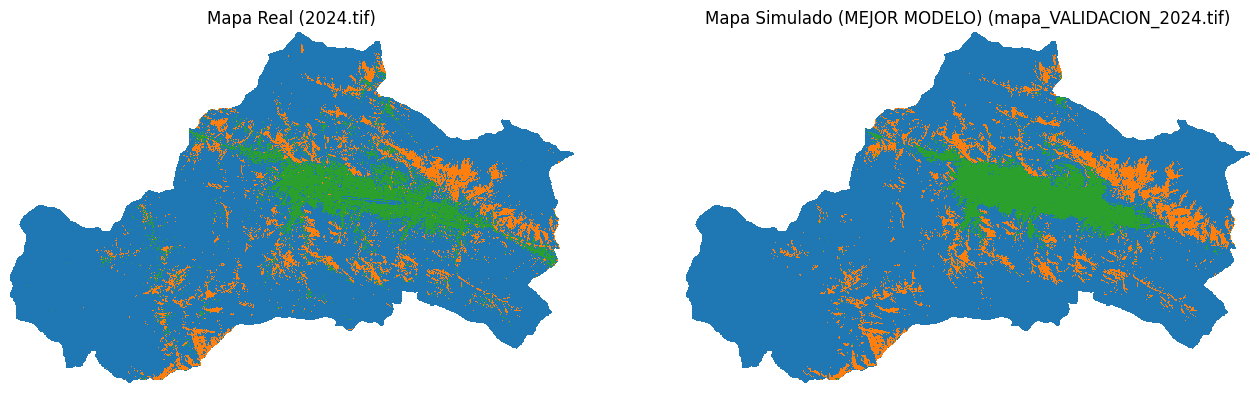

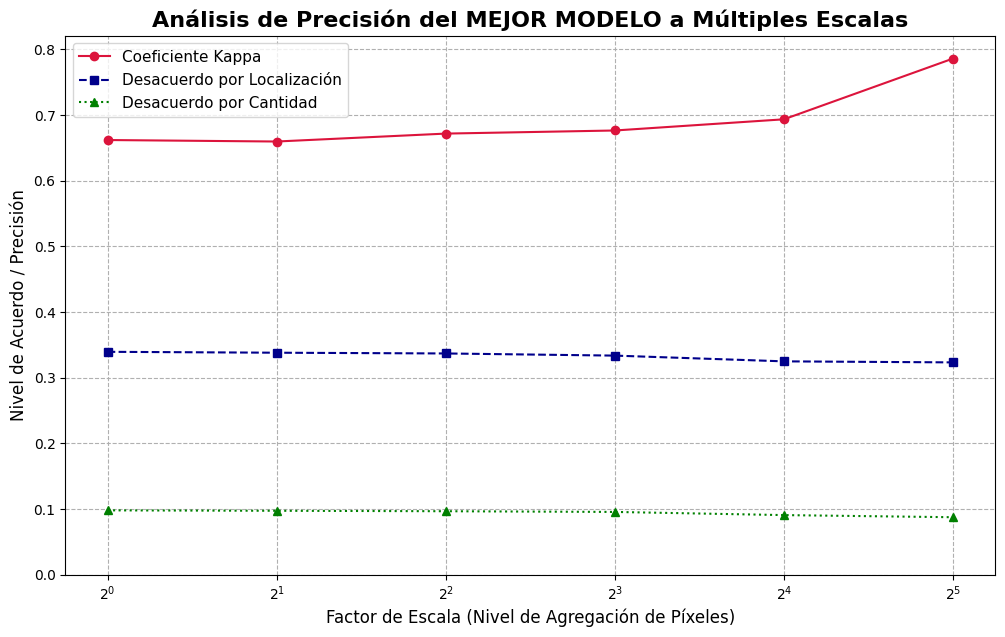

In [ ]:
import os
import pickle
import pandas as pd
import numpy as np
import traceback
from osgeo import gdal
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# --- Auxiliary function to save potential TIFs (float) ---
def guardar_potencial_tif(mapa_array, geodata, ruta_salida):
    """
    Guarda un array de numpy (float) como un GeoTIF de 1 banda,
    convirtiendo np.nan a -9999 y estableciéndolo como NoData.
    """
    try:
        driver = gdal.GetDriverByName('GTiff')
        out_ds = driver.Create(ruta_salida,
                             geodata['xSize'],
                             geodata['ySize'],
                             1,
                             gdal.GDT_Float32) # Guardar como Float32

        out_ds.SetProjection(geodata['proj'])
        out_ds.SetGeoTransform(geodata['transform'])
        out_band = out_ds.GetRasterBand(1)

        nodata_val = -9999.0
        mapa_array_con_nodata = np.nan_to_num(mapa_array, nan=nodata_val)

        out_band.WriteArray(mapa_array_con_nodata)
        out_band.SetNoDataValue(nodata_val)

        out_ds.FlushCache()
        out_ds = None
    except Exception as e:
        print(f"  -> !!! Error al guardar TIF: {ruta_salida}. Error: {e}")

# --- Definir clases y colores (para los gráficos) ---
clases_lulc = sorted(class_labels.keys())
colores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd'] # Ajusta tus colores
cmap_discreto = ListedColormap(colores[:len(clases_lulc)])
bounds = [c - 0.5 for c in clases_lulc] + [clases_lulc[-1] + 0.5]
norm = BoundaryNorm(bounds, cmap_discreto.N)

# --- INICIO DEL PROCESO ---
try:
    GUARDAR_RESULTADOS_EN_DISCO = False

    print("======================================================================")
    print(" FASE DE REPORTE: VALIDACIÓN INTEGRAL Y PROYECCIÓN FUTURA ")
    print("======================================================================")

    # --- PASO 1: Cargar el mejor modelo guardado ---
    print(f"--- PASO 1: Cargando el mejor modelo desde {rutas['salida_mejor_modelo']} ---")

    if not os.path.exists(rutas['salida_mejor_modelo']):
        raise FileNotFoundError("No se encontró el archivo del modelo. Ejecuta la Celda 4 (bucle) primero.")

    with open(rutas['salida_mejor_modelo'], 'rb') as f:
        data_cargada = pickle.load(f)

    arquitectura_cargada = data_cargada['arquitectura']
    pesos_cargados = data_cargada['weights']

    mlp_cargado = MLP(*arquitectura_cargada)
    mlp_cargado.weights = pesos_cargados

    print(f"Modelo cargado. Arquitectura: {arquitectura_cargada}")

    # --- PASO 2: Recalcular la Matriz de Transición de Entrenamiento ---
    # (Necesaria para la S-Matrix de la validación)
    print("--- PASO 2: Recalculando Crosstable de Entrenamiento (para S-Matrix) ---")
    anho_2004_ct = Raster(rutas["anho_2004"])
    anho_2014_ct = Raster(rutas["anho_2014"])
    crosstable_entrenamiento = CrossTable(anho_2004_ct.getBand(1), anho_2014_ct.getBand(1), expand=True)
    del anho_2004_ct, anho_2014_ct # Liberar memoria
    print("Crosstable de Entrenamiento lista.")


    # ======================================================================================
    # VALIDACIÓN (2014 -> 2024)
    # ======================================================================================

    # --- PASO 3: Validation Simulation (2014 -> 2024) ---
    print("\n--- PASO 3: Re-simulando período de VALIDACIÓN (2014 -> 2024) ---")

    anho_2014_val = Raster(rutas["anho_2014"])
    anho_2024_real = Raster(rutas["anho_2024"]) # Mapa real para validación
    factor_rasters_2014_val = [Raster(path) for path in rutas["factores_2014"]]
    for f in factor_rasters_2014_val: f.normalize(mode='mean')

    simulator_validacion = MlpSimulator(anho_2014_val,
                                        factor_rasters_2014_val,
                                        mlp_cargado,
                                        crosstable_entrenamiento, # Se usa el CT de entrenamiento
                                        ns=parametros["vecindad"],
                                        transition_priority=orden_priorizado)

    predicted_raster_validacion, potential_maps_validacion = simulator_validacion.run_simulation()

    if GUARDAR_RESULTADOS_EN_DISCO:
        predicted_raster_validacion.save(rutas["salida_validacion"])
        print(f"Simulación de validación completada. Mapa guardado en: {rutas['salida_validacion']}")
    else:
        print("Simulación de validación completada (Guardado en disco OMITIDO).")






    # --- PASO 4: Guardar Potenciales de Transición (Validación) como TIF ---
    if GUARDAR_RESULTADOS_EN_DISCO:

      print("\n--- PASO 4: Guardando Potenciales de Transición (Validación) como TIF ---")
      os.makedirs(rutas["salida_potencial_validacion"], exist_ok=True)
      geodata_val = anho_2014_val.getGeodata()
      mapa_partida_val = anho_2014_val.getBand(1)

      for clase_origen in clases_lulc:
          for clase_destino in clases_lulc:
              # if clase_origen == clase_destino: continue # Descomenta para saltar persistencia

              print(f"  Guardando TIF: {clase_origen} -> {clase_destino}")
              mapa_de_potencial = potential_maps_validacion[clase_destino]
              candidate_pixels_mask = (mapa_partida_val.data == clase_origen)

              suitability_map = mapa_de_potencial * candidate_pixels_mask

              # Aplicar máscaras
              suitability_map_float = suitability_map.astype(float)
              suitability_map_float[~candidate_pixels_mask] = np.nan # No-candidatos
              suitability_map_float[mapa_partida_val.mask] = np.nan # NoData original

              # Guardar el TIF
              nombre_archivo = f"potencial_val_{clase_origen}_a_{clase_destino}.tif"
              ruta_salida_tif = os.path.join(rutas["salida_potencial_validacion"], nombre_archivo)
              guardar_potencial_tif(suitability_map_float, geodata_val, ruta_salida_tif)

      print(f"Potenciales de Validación guardados en: {rutas['salida_potencial_validacion']}")



      print("\n--- Guardando Potenciales PUROS (Validación) como TIF ---")

      for clase_destino, potential_array in potential_maps_validacion.items():
          print(f"  Guardando TIF PURO: SER Clase {clase_destino}")

          # Crear el array con NaNs
          potential_map_float = potential_array.astype(float)
          # Opcional: convierte ceros a NaN como en tu gráfico
          potential_map_float[potential_map_float == 0] = np.nan
          # Aplicar la máscara NoData original
          potential_map_float[mapa_partida_val.mask] = np.nan

          # Guardar el TIF
          nombre_archivo = f"potencial_val_PURO_ser_{clase_destino}.tif"
          ruta_salida_tif = os.path.join(rutas["salida_potencial_validacion"], nombre_archivo)
          guardar_potencial_tif(potential_map_float, geodata_val, ruta_salida_tif)

      print(f"Potenciales PUROS de Validación guardados.")

    else:
        print("\n--- PASO 4: Omitido (GUARDAR_RESULTADOS_EN_DISCO = False) ---")


    # --- PASO 5: Ejecución de VALIDACIÓN INTEGRAL (ex-Celda 7) ---
    print("\n--- PASO 5: Ejecutando VALIDACIÓN INTEGRAL (Real 2024 vs. Simulado 2024) ---")

    real_array = anho_2024_real.getBand(1)
    predicted_array = predicted_raster_validacion.getBand(1)

    mascara_comun = real_array.mask | predicted_array.mask
    real_validos = real_array.data[~mascara_comun]
    predicted_validos = predicted_array.data[~mascara_comun]

    # 5.1. Métricas Kappa y Desglose
    print("\n  --- 5.1. Métricas de Precisión y Desglose de Kappa ---")
    N = len(real_validos)
    Po = accuracy_score(real_validos, predicted_validos)
    etiquetas = sorted(list(set(np.concatenate((real_validos, predicted_validos)))))
    conf_matrix = confusion_matrix(real_validos, predicted_validos, labels=etiquetas)
    sum_real = conf_matrix.sum(axis=1)
    sum_pred = conf_matrix.sum(axis=0)
    Pe = np.sum(sum_real * sum_pred) / (N**2)
    P_quantity = np.sum(np.minimum(sum_real, sum_pred)) / N
    Kstandard = (Po - Pe) / (1 - Pe) if (1 - Pe) != 0 else np.nan
    Khisto = (P_quantity - Pe) / (1 - Pe) if (1 - Pe) != 0 else np.nan
    Kloc = (Po - P_quantity) / (1 - P_quantity) if (1 - P_quantity) != 0 else np.nan
    print(f"  Certeza General (Overall Accuracy): {Po:.4f} ({Po:.2%})")
    print(f"  Coeficiente Kappa Estándar (Kstandard): {Kstandard:.4f}")
    print(f"  Kappa de Histograma (Khisto): {Khisto:.4f}")
    print(f"  Kappa de Localización (Kloc): {Kloc:.4f}")

    # 5.2. Matriz de Confusión
    print("\n  --- 5.2. Matriz de Confusión ---")
    conf_df = pd.DataFrame(conf_matrix, index=[f'Real_{l}' for l in etiquetas],
                           columns=[f'Pred_{l}' for l in etiquetas])
    print(conf_df)

    # 5.3. Precisión Difusa
    precision_difusa_3x3 = calcular_precision_difusa(real_array, predicted_array, tamano_ventana=1)
    print(f"\n  --- 5.3. Métrica de Precisión Difusa (con Vecindad) ---")
    print(f"  Precisión Difusa (Fuzzy Accuracy 3x3): {precision_difusa_3x3:.4f} ({precision_difusa_3x3:.2%})")

    # 5.4. Kappa Espacial Difuso
    print("\n  --- 5.4. Kappa Espacial Difuso (con Matriz de Similitud) ---")
    T = crosstable_entrenamiento.getCrosstable() # Usa el crosstable del Paso 2
    clases_T = crosstable_entrenamiento.graduation_x
    n_clases = len(clases_T)
    S_matrix = np.eye(n_clases, dtype=float)
    for i in range(n_clases):
        for j in range(n_clases):
            if i != j:
                num = T[i, j] + T[j, i]
                den = T[i, i] + T[j, j] + T[i, j] + T[j, i]
                S_matrix[i, j] = num / den if den > 0 else 0
    print("  Matriz de Similitud (S-Matrix):")
    print(pd.DataFrame(S_matrix, index=clases_T, columns=clases_T).round(3))

    kappa_fuzzy_spatial = spatial_fuzzy_kappa(anho_2024_real, predicted_raster_validacion,
                                              neighbourhood=1,
                                              similarity_matrix=S_matrix)
    print(f"\n  Fuzzy Kappa Espacial (vecindad=1): {kappa_fuzzy_spatial:.4f}")

    # 5.5. Validación Multiescala
    print("\n  --- 5.5. Validación Multiescala (Kappa & Error Budget) ---")
    validator = ValidationMultiScale(anho_2024_real, predicted_raster_validacion)
    validation_results_df = validator.run_analysis(iterations=6, scale_factor=2)
    print("  Resultados de la Validación Multiescala:")
    print(validation_results_df.to_string(index=False, float_format="%.4f"))

    # 5.6. Gráficos de Validación
    print("\n  --- 5.6. Visualización de Resultados de Validación ---")
    fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    ax1.imshow(real_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax1.set_title(f'Mapa Real ({os.path.basename(rutas["anho_2024"])})')
    ax1.axis('off')
    ax2.imshow(predicted_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax2.set_title(f'Mapa Simulado (MEJOR MODELO) ({os.path.basename(rutas["salida_validacion"])})')
    ax2.axis('off')
    plt.show()

    fig2, ax = plt.subplots(figsize=(12, 7))
    ax.plot(validation_results_df['Escala'], validation_results_df['Kappa'], marker='o', color='crimson', label='Coeficiente Kappa')
    ax.plot(validation_results_df['Escala'], validation_results_df['Acuerdo Total (MedMed)'], marker='s', linestyle='--', color='darkblue', label='Desacuerdo por Localización')
    ax.plot(validation_results_df['Escala'], validation_results_df['Acuerdo por Cantidad (NoMed)'], marker='^', linestyle=':', color='green', label='Desacuerdo por Cantidad')
    ax.set_title('Análisis de Precisión del MEJOR MODELO a Múltiples Escalas', fontsize=16, weight='bold')
    ax.set_xlabel('Factor de Escala (Nivel de Agregación de Píxeles)', fontsize=12)
    ax.set_ylabel('Nivel de Acuerdo / Precisión', fontsize=12)
    ax.set_ylim(bottom=min(0, validation_results_df['Kappa'].min() - 0.05))
    ax.legend(fontsize=11)
    ax.set_xscale('log', base=2)
    ax.grid(True, which="both", ls="--")
    plt.show()
    print("Validación integral finalizada.")


    # ======================================================================================
    # PROYECCIÓN (2024 -> 2034)
    # ======================================================================================

    # --- PASO 6: Simulación de PROYECCIÓN (2024 -> 2034) ---
    print("\n--- PASO 6: Ejecutando simulación de PROYECCIÓN (2024 -> 2034) ---")

    anho_2014_proy = Raster(rutas["anho_2014"]) # Para la demanda
    anho_2024_proy = Raster(rutas["anho_2024"]) # Estado inicial
    factor_rasters_2024_proy = [Raster(path) for path in rutas["factores_2024"]]
    for f in factor_rasters_2024_proy: f.normalize(mode='mean')

    crosstable_proyeccion = CrossTable(anho_2014_proy.getBand(1), anho_2024_proy.getBand(1), expand=True)

    print("  Matriz de demanda de cambio (2014->2024) para la proyección 2024->2034:")
    print(pd.DataFrame(crosstable_proyeccion.getCrosstable(),
                       index=crosstable_proyeccion.graduation_x,
                       columns=crosstable_proyeccion.graduation_y))

    simulator_proyeccion = MlpSimulator(anho_2024_proy,
                                        factor_rasters_2024_proy,
                                        mlp_cargado,
                                        crosstable_proyeccion,
                                        ns=parametros["vecindad"],
                                        transition_priority=orden_priorizado)

    predicted_raster_proyeccion, potential_maps_proyeccion = simulator_proyeccion.run_simulation()

    if GUARDAR_RESULTADOS_EN_DISCO:
        predicted_raster_proyeccion.save(rutas["salida_proyeccion"])
        print(f"Proyección 2034 finalizada. Mapa guardado en: {rutas['salida_proyeccion']}")
    else:
        print("Proyección 2034 finalizada (Guardado en disco OMITIDO).")



    # --- PASO 7: Guardar Potenciales de Transición (Proyección) ---
    if GUARDAR_RESULTADOS_EN_DISCO:
      print("\n--- PASO 7: Guardando Potenciales de Transición (Proyección) como TIF ---")
      os.makedirs(rutas["salida_potencial_proyeccion"], exist_ok=True)
      geodata_proy = anho_2024_proy.getGeodata()
      mapa_partida_proy = anho_2024_proy.getBand(1)

      for clase_origen in clases_lulc:
          for clase_destino in clases_lulc:
              # if clase_origen == clase_destino: continue # Descomenta para saltar persistencia

              print(f"  Guardando TIF: {clase_origen} -> {clase_destino}")
              mapa_de_potencial = potential_maps_proyeccion[clase_destino]
              candidate_pixels_mask = (mapa_partida_proy.data == clase_origen)

              suitability_map = mapa_de_potencial * candidate_pixels_mask

              # Aplicar máscaras
              suitability_map_float = suitability_map.astype(float)
              suitability_map_float[~candidate_pixels_mask] = np.nan # No-candidatos
              suitability_map_float[mapa_partida_proy.mask] = np.nan # NoData original

              # Guardar el TIF
              nombre_archivo = f"potencial_proy_{clase_origen}_a_{clase_destino}.tif"
              ruta_salida_tif = os.path.join(rutas["salida_potencial_proyeccion"], nombre_archivo)
              guardar_potencial_tif(suitability_map_float, geodata_proy, ruta_salida_tif)

      print(f"Potenciales de Proyección guardados en: {rutas['salida_potencial_proyeccion']}")


      print("\n--- Guardando Potenciales PUROS (Proyección) como TIF ---")

      for clase_destino, potential_array in potential_maps_proyeccion.items():
          print(f"  Guardando TIF PURO: SER Clase {clase_destino}")

          # Crear el array con NaNs
          potential_map_float = potential_array.astype(float)
          # Opcional: convierte ceros a NaN como en tu gráfico
          potential_map_float[potential_map_float == 0] = np.nan
          # Aplicar la máscara NoData original
          potential_map_float[mapa_partida_proy.mask] = np.nan

          # Guardar el TIF
          nombre_archivo = f"potencial_proy_PURO_ser_{clase_destino}.tif"
          ruta_salida_tif = os.path.join(rutas["salida_potencial_proyeccion"], nombre_archivo)
          guardar_potencial_tif(potential_map_float, geodata_proy, ruta_salida_tif)

      print(f"Potenciales PUROS de Proyección guardados.")
    else:
        print("\n--- PASO 7: Omitido (GUARDAR_RESULTADOS_EN_DISCO = False) ---")


except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR CRÍTICO DURANTE LA EJECUCIÓN !!!!!!")
    traceback.print_exc()

print("\n======================================================================")
print("  PROCESO COMPLETO FINALIZADO ")
print("======================================================================")

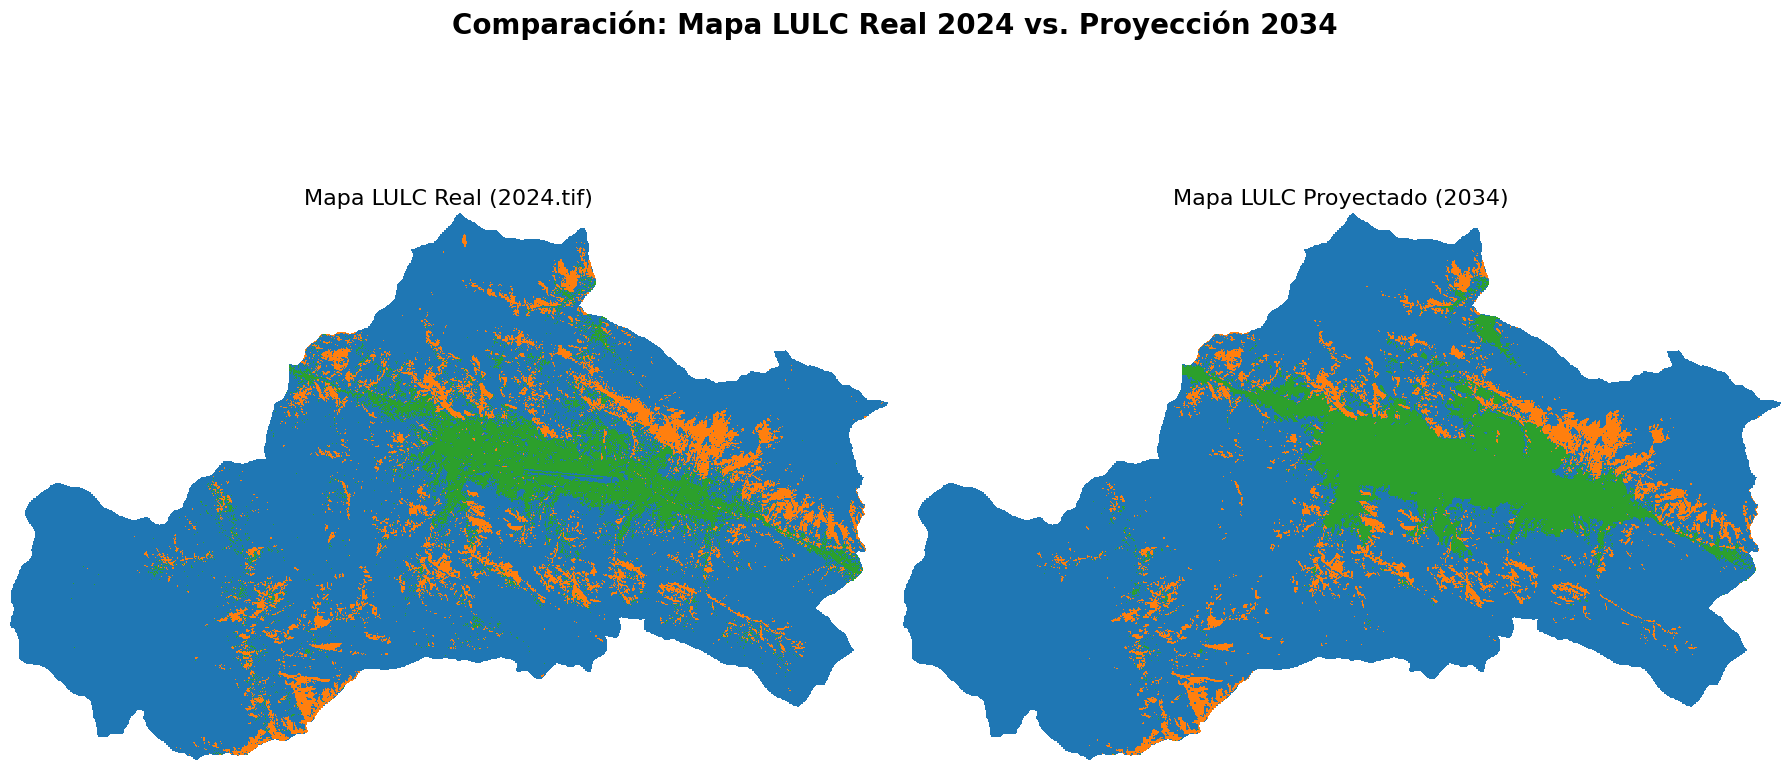

In [ ]:
import os
import pickle
import pandas as pd
import numpy as np
import traceback
from osgeo import gdal
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# --- Auxiliary function to save potential TIFs (float) ---
def guardar_potencial_tif(mapa_array, geodata, ruta_salida):
    """
    Guarda un array de numpy (float) como un GeoTIF de 1 banda,
    convirtiendo np.nan a -9999 y estableciéndolo como NoData.
    """
    try:
        driver = gdal.GetDriverByName('GTiff')
        out_ds = driver.Create(ruta_salida,
                             geodata['xSize'],
                             geodata['ySize'],
                             1,
                             gdal.GDT_Float32) # Guardar como Float32

        out_ds.SetProjection(geodata['proj'])
        out_ds.SetGeoTransform(geodata['transform'])
        out_band = out_ds.GetRasterBand(1)

        nodata_val = -9999.0
        mapa_array_con_nodata = np.nan_to_num(mapa_array, nan=nodata_val)

        out_band.WriteArray(mapa_array_con_nodata)
        out_band.SetNoDataValue(nodata_val)

        out_ds.FlushCache()
        out_ds = None
    except Exception as e:
        print(f"  -> !!! Error al guardar TIF: {ruta_salida}. Error: {e}")

# --- Definir clases y colores (para los gráficos) ---
# Asegúrate de que 'class_labels' está definido globalmente (ej. en tu Celda 1 o 2)
# Ejemplo: class_labels = {1: 'Bosque', 2: 'Agua', 3: 'Urbano'}
clases_lulc = sorted(class_labels.keys())
colores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd'] # Ajusta tus colores
cmap_discreto = ListedColormap(colores[:len(clases_lulc)])
bounds = [c - 0.5 for c in clases_lulc] + [clases_lulc[-1] + 0.5]
norm = BoundaryNorm(bounds, cmap_discreto.N)

# --- INICIO DEL PROCESO ---
try:
    print("======================================================================")
    print(" FASE DE PROYECCIÓN Y VISUALIZACIÓN DE MAPAS ")
    print("======================================================================")

    # --- PASO 1: Cargar el mejor modelo guardado ---
    print(f"--- PASO 1: Cargando el mejor modelo desde {rutas['salida_mejor_modelo']} ---")

    if not os.path.exists(rutas['salida_mejor_modelo']):
        raise FileNotFoundError("No se encontró el archivo del modelo. Ejecuta la Celda 4 (bucle) primero.")

    with open(rutas['salida_mejor_modelo'], 'rb') as f:
        data_cargada = pickle.load(f)

    arquitectura_cargada = data_cargada['arquitectura']
    pesos_cargados = data_cargada['weights']

    mlp_cargado = MLP(*arquitectura_cargada)
    mlp_cargado.weights = pesos_cargados

    print(f"Modelo cargado. Arquitectura: {arquitectura_cargada}")

    # --- PASO 2: Recalcular la Matriz de Transición de Entrenamiento para la Proyección ---
    # Esta se usará para calcular la demanda de la proyección 2024->2034
    print("--- PASO 2: Recalculando Crosstable de Entrenamiento (para S-Matrix de Proyección) ---")
    anho_2014_ct_proy = Raster(rutas["anho_2014"])
    anho_2024_ct_proy = Raster(rutas["anho_2024"])
    crosstable_proyeccion = CrossTable(anho_2014_ct_proy.getBand(1), anho_2024_ct_proy.getBand(1), expand=True)
    del anho_2014_ct_proy, anho_2024_ct_proy # Liberar memoria
    print("Crosstable para la proyección 2024->2034 lista.")

    # ======================================================================================
    # PROYECCIÓN (2024 -> 2034)
    # ======================================================================================

    # --- PASO 3: Simulación de PROYECCIÓN (2024 -> 2034) ---
    print("\n--- PASO 3: Ejecutando simulación de PROYECCIÓN (2024 -> 2034) ---")

    anho_2024_proy_inicial = Raster(rutas["anho_2024"]) # Estado inicial para la proyección
    factor_rasters_2024_proy = [Raster(path) for path in rutas["factores_2024"]]
    for f in factor_rasters_2024_proy: f.normalize(mode='mean')

    print("  Matriz de demanda de cambio (2014->2024) para la proyección 2024->2034:")
    print(pd.DataFrame(crosstable_proyeccion.getCrosstable(),
                       index=crosstable_proyeccion.graduation_x,
                       columns=crosstable_proyeccion.graduation_y))

    simulator_proyeccion = MlpSimulator(anho_2024_proy_inicial, # Mapa de partida para la proyección
                                        factor_rasters_2024_proy,
                                        mlp_cargado,
                                        crosstable_proyeccion,
                                        ns=parametros["vecindad"],
                                        transition_priority=orden_priorizado)

    predicted_raster_proyeccion, _ = simulator_proyeccion.run_simulation() # Ignoramos los potenciales

    predicted_raster_proyeccion.save(rutas["salida_proyeccion"])
    print(f"Proyección 2034 finalizada. Mapa guardado en: {rutas['salida_proyeccion']}")

    # --- PASO 4: Cargar mapa real de 2024 para comparación visual ---
    print(f"\n--- PASO 4: Cargando mapa LULC real de 2024 para visualización ---")
    anho_2024_real_display = Raster(rutas["anho_2024"])

    # --- PASO 5: Generar el gráfico comparativo ---
    print("\n--- PASO 5: Generando visualización comparativa (Real 2024 vs. Proyección 2034) ---")

    real_2024_array = anho_2024_real_display.getBand(1)
    predicted_2034_array = predicted_raster_proyeccion.getBand(1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9)) # Ajustado tamaño para mejor visualización
    fig.suptitle('Comparación: Mapa LULC Real 2024 vs. Proyección 2034', fontsize=20, weight='bold')

    # Mapa Real 2024
    im1 = ax1.imshow(real_2024_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax1.set_title(f'Mapa LULC Real ({os.path.basename(rutas["anho_2024"])})', fontsize=16)
    ax1.axis('off')

    # Mapa Proyección 2034
    ax2.imshow(predicted_2034_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax2.set_title(f'Mapa LULC Proyectado (2034)', fontsize=16)
    ax2.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95]) # Ajustar layout para título
    plt.show()

    print("Visualización de mapas Real 2024 y Proyección 2034 completada.")

except FileNotFoundError as e:
    print(f"\n!!!!!!  ERROR: {e}. Por favor, verifica las rutas o ejecuta las celdas previas. !!!!!!")
except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR CRÍTICO DURANTE LA EJECUCIÓN !!!!!!")
    traceback.print_exc()

print("\n======================================================================")
print("  PROCESO DE PROYECCIÓN Y VISUALIZACIÓN FINALIZADO ")
print("======================================================================")

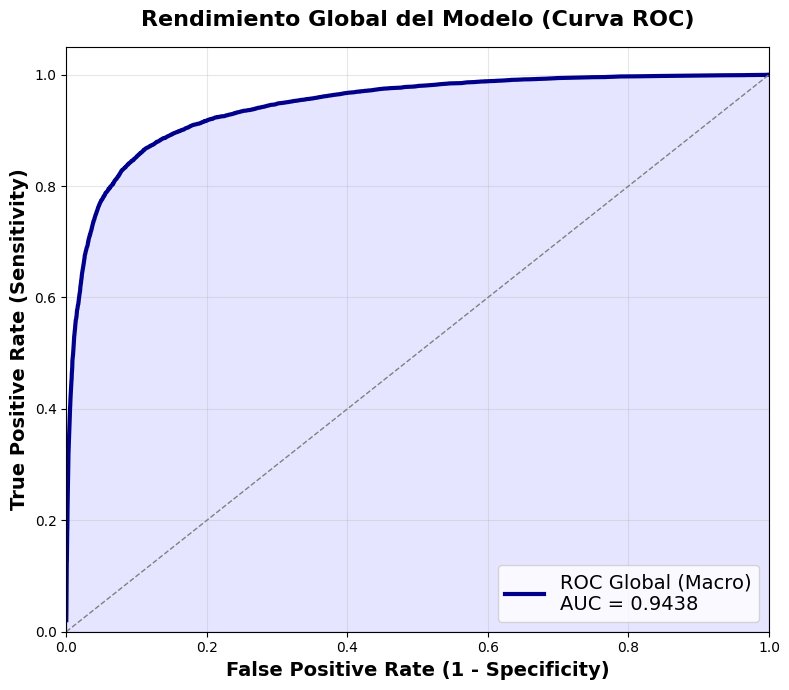

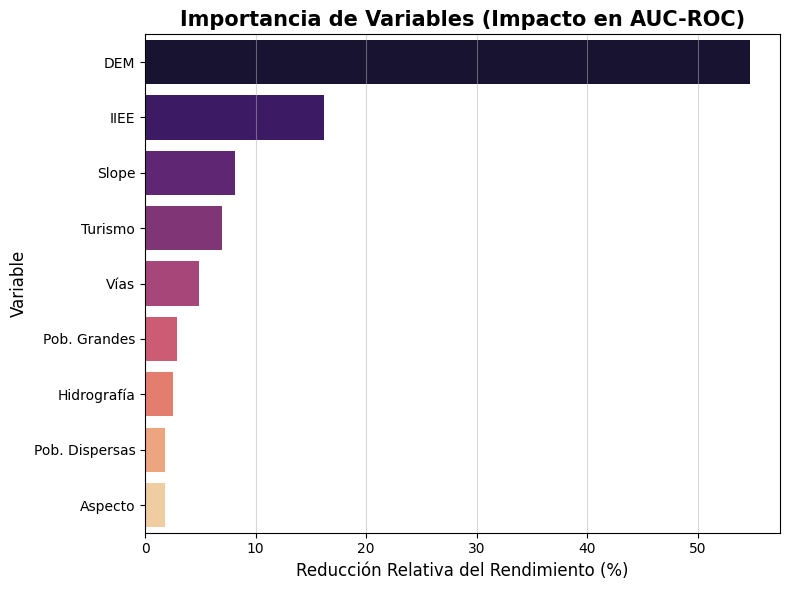

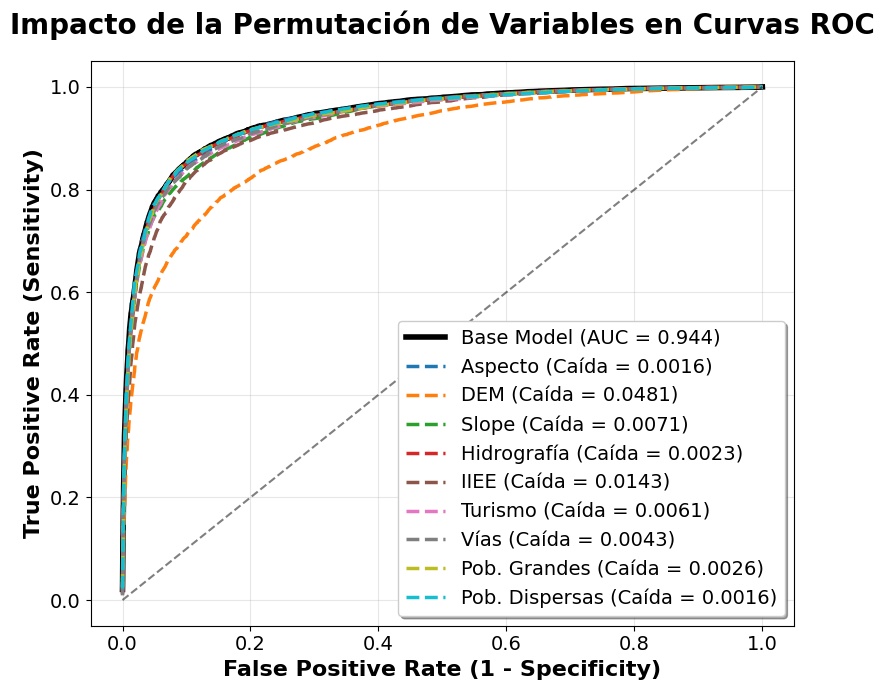

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

# ==============================================================================
# CONFIGURACIÓN Y SEMILLA (REPRODUCIBILIDAD)
# ==============================================================================
SEED = 42
np.random.seed(SEED) # Fija la aleatoriedad de Numpy (Shuffle y Sampling)

print(f"--- INICIANDO ANÁLISIS XAI COMPLETO (SEED={SEED}) ---")

# ==============================================================================
# 1. FUNCIONES AUXILIARES
# ==============================================================================
def softmax(x):
    """Calcula probabilidades Softmax estables."""
    e_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return e_x / np.sum(e_x, axis=1, keepdims=True)

def get_macro_roc(y_true_bin, y_score, n_classes):
    """Calcula FPR, TPR y AUC Macro-Promedio para problemas multiclase."""
    fpr, tpr, roc_auc = {}, {}, {}

    # Calcular para cada clase
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Calcular Macro-Promedio
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes

    return all_fpr, mean_tpr, auc(all_fpr, mean_tpr)

# ==============================================================================
# 2. LÓGICA DE CÁLCULO (TODO EN UNO)
# ==============================================================================
def ejecutar_analisis_completo(mlp_model, sampler, crosstable, n_muestras=9000):

    # --- A. DATA PREPARATION (Se hace una sola vez) ---
    print(f"1. Preparando dataset de validación ({n_muestras} muestras)...")
    output_raster = Raster(rutas["anho_2024"])

    # Reiniciar semilla antes del sampling para asegurar consistencia exacta
    np.random.seed(SEED)
    sampler.setTrainingData(output_raster, mode='Stratified', samples=n_muestras)

    if not sampler.data: raise ValueError("Error: No se obtuvieron datos del Sampler.")

    cats = crosstable.graduation_x
    num_classes = len(cats)
    mapper = {c: i for i, c in enumerate(cats)}

    X_list, y_list = [], []
    for d in sampler.data:
        # Reconstruir Input (State + Factors)
        state_window_flat = []
        for pixel_val in d['state']:
            idx = mapper.get(pixel_val, 0)
            one_hot = np.zeros(num_classes); one_hot[idx] = 1
            state_window_flat.extend(one_hot[:-1])
        full_input = np.concatenate([np.array(state_window_flat), d['factors']])
        X_list.append(full_input)
        y_list.append(mapper.get(d['output'], 0))

    X = np.array(X_list)
    y_true = np.array(y_list)
    y_true_bin = label_binarize(y_true, classes=range(num_classes))

    # Padding (Ajuste de dimensiones si falta espacio)
    dim_esperada = mlp_model.weights[0].shape[0] - 1
    if X.shape[1] < dim_esperada:
        X = np.hstack([X, np.zeros((X.shape[0], dim_esperada - X.shape[1]))])

    # Diccionario para guardar todos los resultados
    resultados = {}

    # --- B. CÁLCULO BASE (MODELO ORIGINAL) ---
    print("2. Calculando rendimiento BASE del modelo...")
    raw_preds = mlp_batch_predict(X, mlp_model.weights)
    prob_preds = softmax(raw_preds)
    base_fpr, base_tpr, base_auc = get_macro_roc(y_true_bin, prob_preds, num_classes)

    resultados["Base"] = {"fpr": base_fpr, "tpr": base_tpr, "auc": base_auc}
    print(f"   -> AUC Global Base: {base_auc:.4f}")

    # --- C. BUCLE DE PERMUTACIÓN (IMPORTANCIA) ---
    print("3. Ejecutando Permutaciones (PFI)...")
    len_state_block = X.shape[1] - len(sampler.data[0]['factors'])
    ns = sampler.ns
    window_pixels = (2*ns + 1)**2
    nombres_factores = ["Aspecto", "DEM", "Slope", "Hidrografía", "IIEE", "Turismo", "Vías", "Pob. Grandes", "Pob. Dispersas"]

    # Usamos un generador de números aleatorios local para las permutaciones
    rng = np.random.RandomState(SEED)

    for i, nombre in enumerate(nombres_factores):
        X_perm = X.copy()
        start_col = len_state_block + (i * window_pixels)
        end_col = start_col + window_pixels

        # Mezclar solo las columnas del factor actual
        cols_to_shuffle = X_perm[:, start_col:end_col]
        rng.shuffle(cols_to_shuffle) # Shuffle determinista usando rng
        X_perm[:, start_col:end_col] = cols_to_shuffle

        # Predecir con datos rotos
        pred_perm = softmax(mlp_batch_predict(X_perm, mlp_model.weights))
        p_fpr, p_tpr, p_auc = get_macro_roc(y_true_bin, pred_perm, num_classes)

        resultados[nombre] = {"fpr": p_fpr, "tpr": p_tpr, "auc": p_auc}
        print(f"   -> {nombre}: AUC cae a {p_auc:.4f} (Delta: {base_auc - p_auc:.4f})")

    return resultados

# ==============================================================================
# 3. EJECUCIÓN Y GENERACIÓN DE GRÁFICOS
# ==============================================================================
try:
    # --- Configurar Sampler ---
    anho_2014_obj = Raster(rutas["anho_2014"])
    factores_obj = [Raster(p) for p in rutas["factores_2014"]]
    for f in factores_obj: f.normalize(mode='mean')
    sampler_xai = Sampler(anho_2014_obj, factores_obj, ns=parametros["vecindad"])

    # --- Ejecutar Cálculos ---
    data_res = ejecutar_analisis_completo(mlp_cargado, sampler_xai, crosstable_entrenamiento)

    # Extraer datos Base
    base_data = data_res["Base"]
    factores_keys = [k for k in data_res.keys() if k != "Base"]

    # ---------------------------------------------------------
    # FIGURA 1: CURVA ROC GLOBAL (STANDALONE)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 7))
    plt.plot(base_data["fpr"], base_data["tpr"], color='darkblue', lw=3,
             label=f'ROC Global (Macro)\nAUC = {base_data["auc"]:.4f}')
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    plt.fill_between(base_data["fpr"], base_data["tpr"], alpha=0.1, color='blue')

    plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=14, fontweight='bold')
    plt.ylabel('True Positive Rate (Sensitivity)', fontsize=14, fontweight='bold')
    plt.title('Rendimiento Global del Modelo (Curva ROC)', fontsize=16, fontweight='bold', pad=15)
    plt.legend(loc="lower right", fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # FIGURA 2: RANKING DE IMPORTANCIA (BARRAS + TABLA)
    # ---------------------------------------------------------
    # Crear DataFrame de Importancia
    imp_list = []
    for nombre in factores_keys:
        drop = base_data["auc"] - data_res[nombre]["auc"]
        imp_list.append({'Variable': nombre, 'Caída AUC': drop})

    df_imp = pd.DataFrame(imp_list)
    # Evitar valores negativos pequeños por ruido numérico
    df_imp['Caída AUC'] = df_imp['Caída AUC'].apply(lambda x: x if x > 0 else 0)
    df_imp['Importancia Relativa (%)'] = (df_imp['Caída AUC'] / df_imp['Caída AUC'].sum()) * 100
    df_imp = df_imp.sort_values(by='Caída AUC', ascending=False)

    print("\n" + "="*50)
    print(" RANKING DE VARIABLES (IMPACTO EN AUC)")
    print("="*50)
    print(df_imp.to_string(index=False, formatters={'Caída AUC': '{:,.4f}'.format, 'Importancia Relativa (%)': '{:,.2f}'.format}))

    plt.figure(figsize=(8, 6))
    sns.barplot(x='Importancia Relativa (%)', y='Variable', data=df_imp, palette='magma')
    plt.title('Importancia de Variables (Impacto en AUC-ROC)', fontsize=15, fontweight='bold')
    plt.xlabel('Reducción Relativa del Rendimiento (%)', fontsize=12)
    plt.ylabel('Variable', fontsize=12)
    plt.grid(True, axis='x', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # FIGURA 3: COMPARATIVA DE CURVAS (XAI DETALLADO)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 7))

    # Plot Base
    plt.plot(base_data["fpr"], base_data["tpr"],
             label=f'Base Model (AUC = {base_data["auc"]:.3f})',
             color='black', linewidth=4, linestyle='-')

    # Plot Factores
    colors = plt.cm.tab10(np.linspace(0, 1, len(factores_keys)))
    for (nombre, color) in zip(factores_keys, colors):
        d = data_res[nombre]
        drop = base_data["auc"] - d["auc"]
        plt.plot(d["fpr"], d["tpr"],
                 label=f'{nombre} (Caída = {drop:.4f})',
                 color=color, linewidth=2.5, linestyle='--')

    plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5)

    # Estilos Grandes
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=16, fontweight='bold')
    plt.ylabel('True Positive Rate (Sensitivity)', fontsize=16, fontweight='bold')
    plt.title('Impacto de la Permutación de Variables en Curvas ROC', fontsize=20, fontweight='bold', pad=20)
    plt.xticks(fontsize=14); plt.yticks(fontsize=14)
    plt.legend(loc="lower right", fontsize=14, frameon=True, shadow=True)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

except Exception as e:
    import traceback
    print(f"Error Crítico: {e}")
    traceback.print_exc()

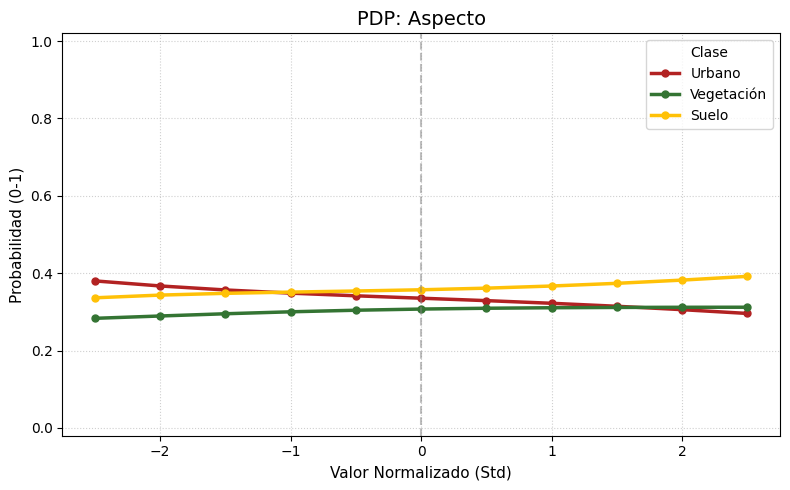

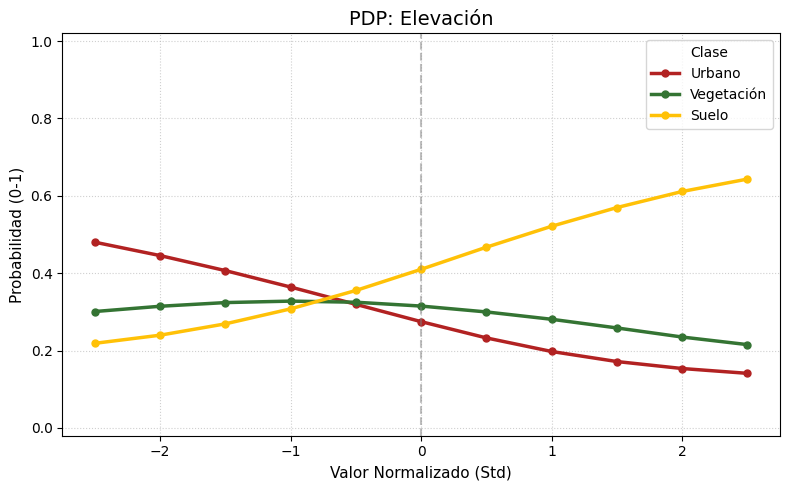

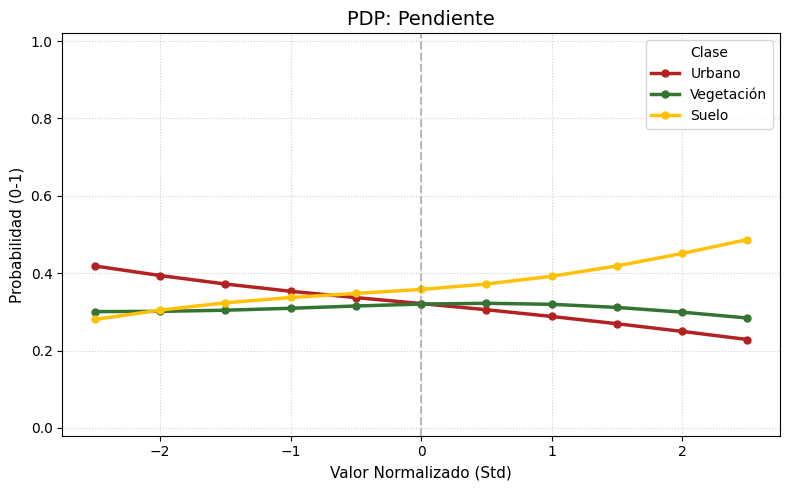

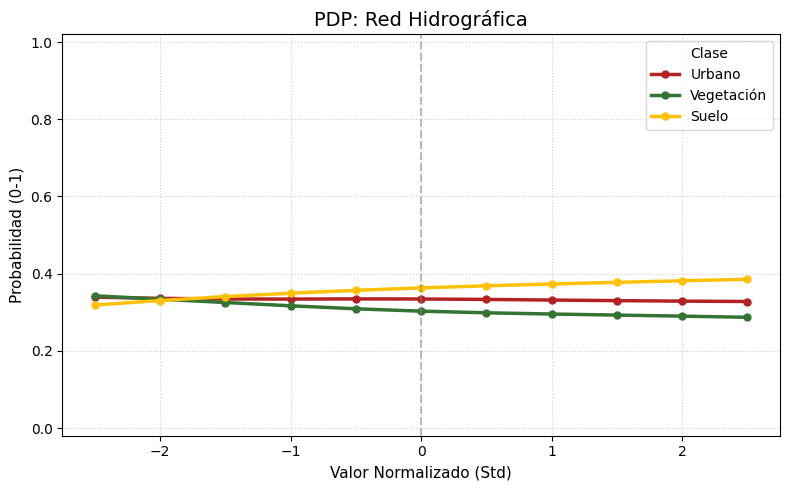

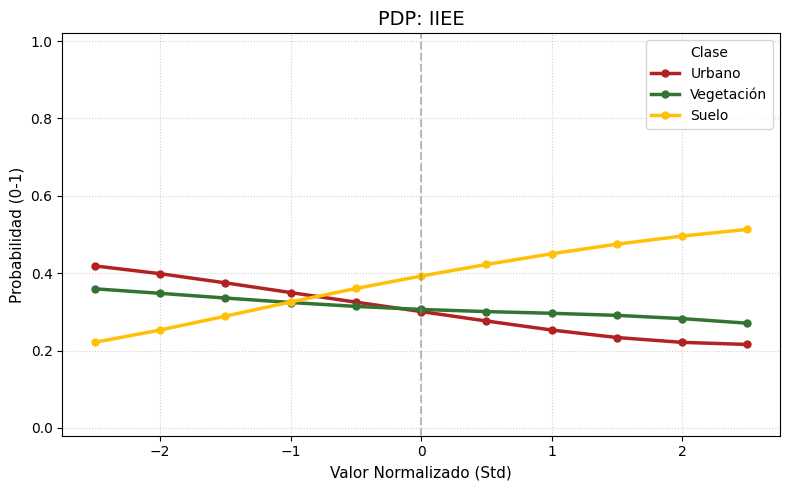

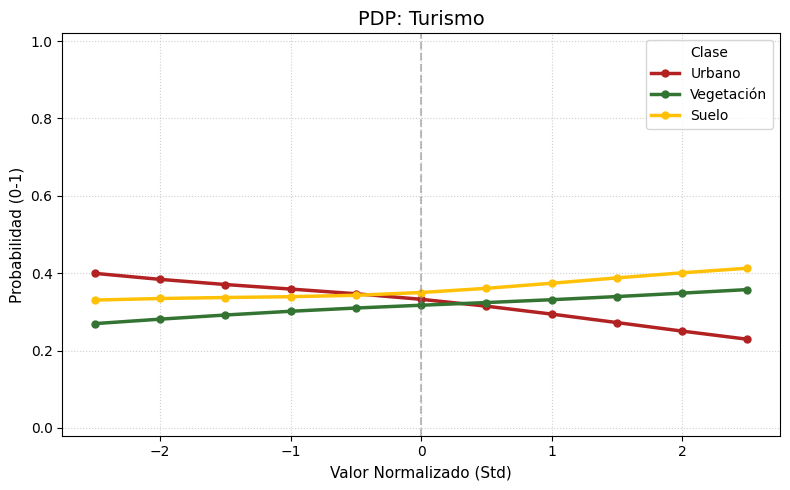

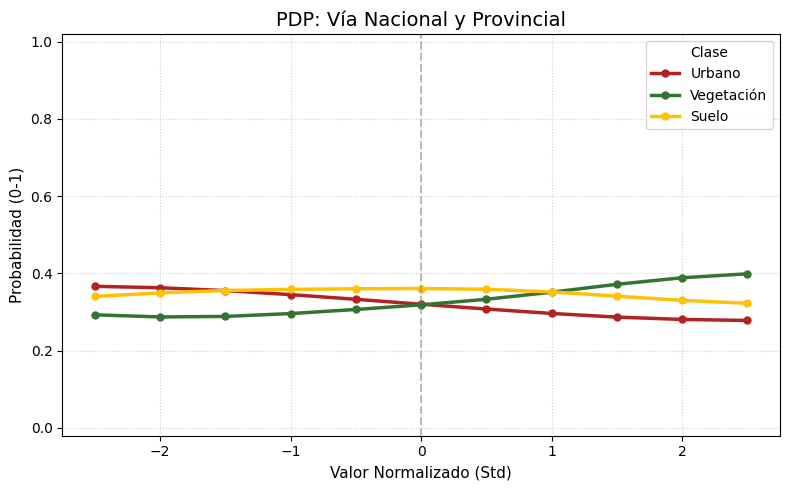

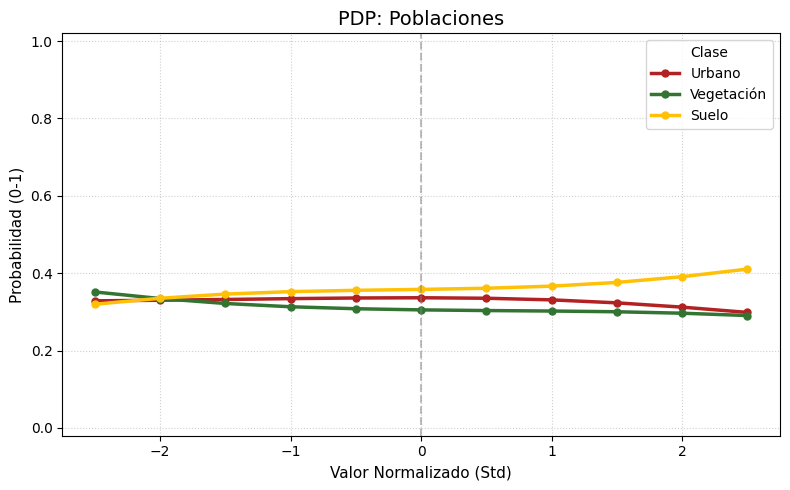

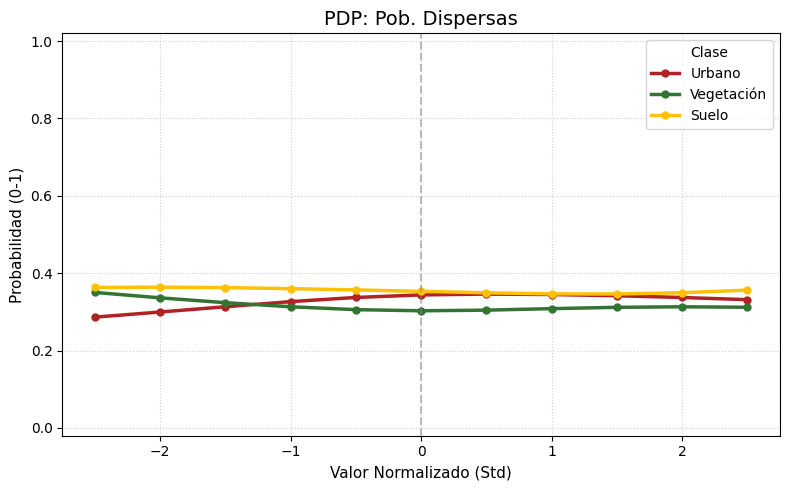

In [ ]:
# ==============================================================================
# 8. ANÁLISIS PDP, REPRODUCIBLE
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import traceback

# --- CONFIGURACIÓN DE CLASES ---
CLASES_INFO = {
    0: {"nombre": "Urbano", "color": "#b22222"},      # Rojo
    1: {"nombre": "Vegetación", "color": "#347433"},  # Verde
    2: {"nombre": "Suelo", "color": "#ffc107"}        # Marrón
}

def softmax(x):
    """Convierte puntajes crudos en probabilidades reales (suma 1)."""
    e_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return e_x / np.sum(e_x, axis=1, keepdims=True)

def ejecutar_analisis_completo_pdp(mlp_model, sampler, lista_nombres, crosstable, muestras=9000):
    # FIJAR SEMILLA PARA REPRODUCIBILIDAD
    np.random.seed(42)

    print(f"--- INICIANDO ANÁLISIS PDP (N={muestras}, Seed=42) ---")

    # 1. DATA PREPARATION BASE
    print(f"Recolectando muestras base...")
    output_raster = Raster(rutas["anho_2024"])
    sampler.setTrainingData(output_raster, mode='Stratified', samples=muestras)

    if not sampler.data: raise ValueError("No hay datos en el sampler.")

    cats = crosstable.graduation_x
    mapper = {c: i for i, c in enumerate(cats)}
    num_cats = len(cats)

    X_samples = []
    for d in sampler.data:
        state_window_flat = []
        for pixel_val in d['state']:
            idx = mapper.get(pixel_val, 0)
            one_hot = np.zeros(num_cats)
            one_hot[idx] = 1
            state_window_flat.extend(one_hot[:-1])

        full_input = np.concatenate([np.array(state_window_flat), d['factors']])
        X_samples.append(full_input)

    X_base = np.array(X_samples)

    # Padding
    dim_esperada = mlp_model.weights[0].shape[0] - 1
    if X_base.shape[1] < dim_esperada:
        diff = dim_esperada - X_base.shape[1]
        X_base = np.hstack([X_base, np.zeros((X_base.shape[0], diff))])

    len_state_block = X_base.shape[1] - len(sampler.data[0]['factors'])
    ns = sampler.ns
    window_pixels = (2*ns + 1)**2

    # 2. BUCLE PRINCIPAL
    for i, nombre_variable in enumerate(lista_nombres):
        print(f"\nProcesando: {nombre_variable}...")

        start_col = len_state_block + (i * window_pixels)
        end_col = start_col + window_pixels

        rango_valores = np.linspace(-2.5, 2.5, 11)

        resultados_probs = {k: [] for k in CLASES_INFO.keys()}

        for valor in rango_valores:
            X_test = X_base.copy()
            if end_col <= X_test.shape[1]:
                X_test[:, start_col:end_col] = valor

            raw_scores = mlp_batch_predict(X_test, mlp_model.weights)
            probs_reales = softmax(raw_scores)

            for idx_clase in CLASES_INFO.keys():
                if idx_clase < probs_reales.shape[1]:
                    resultados_probs[idx_clase].append(np.mean(probs_reales[:, idx_clase]))
                else:
                    resultados_probs[idx_clase].append(0.0)

        # 3. TABLA RESUMIDA
        data_frame_dict = {"Valor Std": rango_valores}
        for idx_clase, info in CLASES_INFO.items():
            data_frame_dict[f"{info['nombre']}"] = resultados_probs[idx_clase]

        df_resultados = pd.DataFrame(data_frame_dict)

        print(f"\n{'='*60}")
        print(f" TABLA: {nombre_variable.upper()}")
        print(f"{'='*60}")
        print(df_resultados.to_string(index=False, formatters={
            'Valor Std': '{:,.1f}'.format,  # Solo 1 decimal para el valor X
            'Urbano': '{:,.4f}'.format,
            'Vegetación': '{:,.4f}'.format,
            'Suelo': '{:,.4f}'.format
        }))
        print(f"{'='*60}\n")

        # 4. GRÁFICO
        plt.figure(figsize=(8, 5))
        for idx_clase, info in CLASES_INFO.items():
            y_vals = resultados_probs[idx_clase]
            plt.plot(rango_valores, y_vals,
                     label=info['nombre'],
                     color=info['color'],
                     linewidth=2.5,
                     marker='o', markersize=5) # Puntos más visibles

        plt.title(f'PDP: {nombre_variable}', fontsize=14)
        plt.xlabel('Valor Normalizado (Std)', fontsize=11)
        plt.ylabel('Probabilidad (0-1)', fontsize=11)
        plt.ylim(-0.02, 1.02)
        plt.legend(title="Clase", fontsize=10)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

# --- EJECUCIÓN ---
try:
    nombres_factores = ["Aspecto", "Elevación", "Pendiente", "Red Hidrográfica", "IIEE", "Turismo", "Vía Nacional y Provincial", "Poblaciones", "Pob. Dispersas"]

    anho_2014_obj = Raster(rutas["anho_2014"])
    factores_obj = [Raster(p) for p in rutas["factores_2014"]]
    for f in factores_obj: f.normalize(mode='mean')

    sampler_pdp = Sampler(anho_2014_obj, factores_obj, ns=parametros["vecindad"])

    ejecutar_analisis_completo_pdp(mlp_cargado,
                                   sampler_pdp,
                                   nombres_factores,
                                   crosstable_entrenamiento,
                                   muestras=9000)

except Exception as e:
    print(f"Error Crítico: {e}")
    traceback.print_exc()

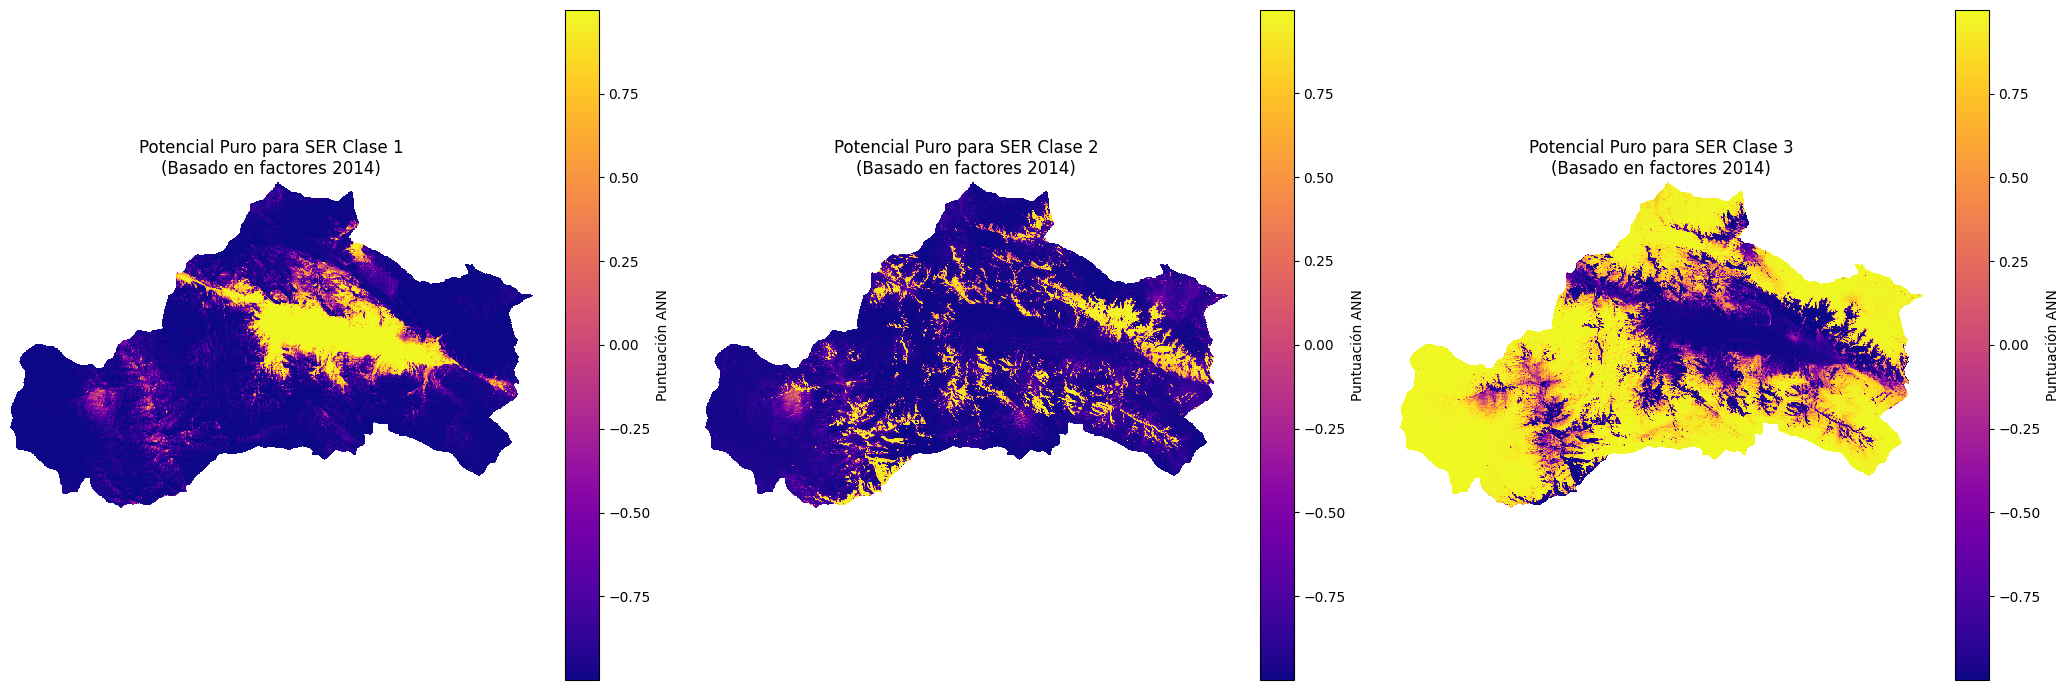

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("\n--- VISUALIZACIÓN: Mapas de Potencial Puro (Validación 2024) ---")
print("Estos son los mapas de 'Aptitud para SER' generados por el MLP para el período 2014->2024")

try:
    # Assuming that 'potential_maps_validacion' exists
    num_clases = len(potential_maps_validacion)
    fig, axes = plt.subplots(1, num_clases, figsize=(num_clases * 7, 7))

    if num_clases == 1: # Manejar el caso de una sola clase
        axes = [axes]

    clases_ordenadas = sorted(potential_maps_validacion.keys())

    for i, clase_destino in enumerate(clases_ordenadas):
        ax = axes[i]
        mapa_potencial = potential_maps_validacion[clase_destino]

        # Reemplazar ceros con NaN para una mejor visualización (opcional)
        mapa_potencial_viz = mapa_potencial.astype(float)
        mapa_potencial_viz[mapa_potencial_viz == 0] = np.nan

        im = ax.imshow(mapa_potencial_viz, cmap='plasma', interpolation='nearest')
        ax.set_title(f'Potencial Puro para SER Clase {clase_destino}\n(Basado en factores 2014)')
        ax.axis('off')
        fig.colorbar(im, ax=ax, label='Puntuación ANN')

    plt.tight_layout()
    plt.show()

except NameError:
    print("ERROR: La variable 'potential_maps_validacion' no está definida.")
except Exception as e:
    print(f"Ocurrió un error al graficar: {e}")
    traceback.print_exc()

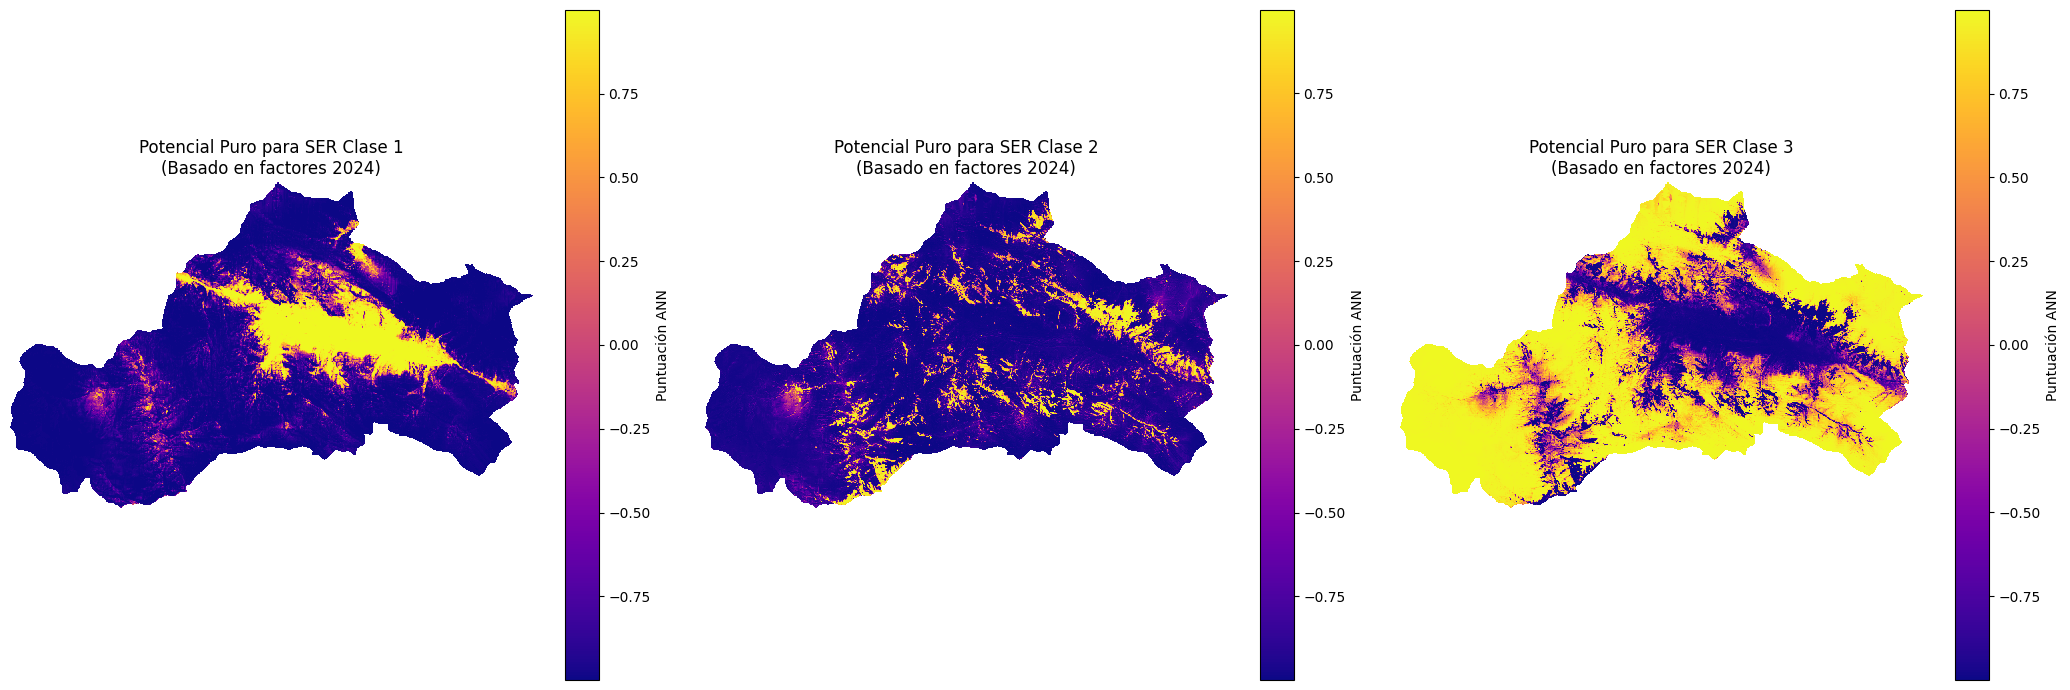

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("\n--- VISUALIZACIÓN: Mapas de Potencial Puro (Proyección 2034) ---")
print("Estos son los mapas de 'Aptitud para SER' generados por el MLP para el período 2024->2034")

try:
    # Assuming that 'potential_maps_proyeccion' exists
    num_clases = len(potential_maps_proyeccion)
    fig, axes = plt.subplots(1, num_clases, figsize=(num_clases * 7, 7))

    if num_clases == 1: # Manejar el caso de una sola clase
        axes = [axes]

    clases_ordenadas = sorted(potential_maps_proyeccion.keys())

    for i, clase_destino in enumerate(clases_ordenadas):
        ax = axes[i]
        mapa_potencial = potential_maps_proyeccion[clase_destino]

        # Reemplazar ceros con NaN para una mejor visualización (opcional)
        mapa_potencial_viz = mapa_potencial.astype(float)
        mapa_potencial_viz[mapa_potencial_viz == 0] = np.nan

        im = ax.imshow(mapa_potencial_viz, cmap='plasma', interpolation='nearest')
        ax.set_title(f'Potencial Puro para SER Clase {clase_destino}\n(Basado en factores 2024)')
        ax.axis('off')
        fig.colorbar(im, ax=ax, label='Puntuación ANN')

    plt.tight_layout()
    plt.show()

except NameError:
    print("ERROR: La variable 'potential_maps_proyeccion' no está definida.")
except Exception as e:
    print(f"Ocurrió un error al graficar: {e}")
    traceback.print_exc()

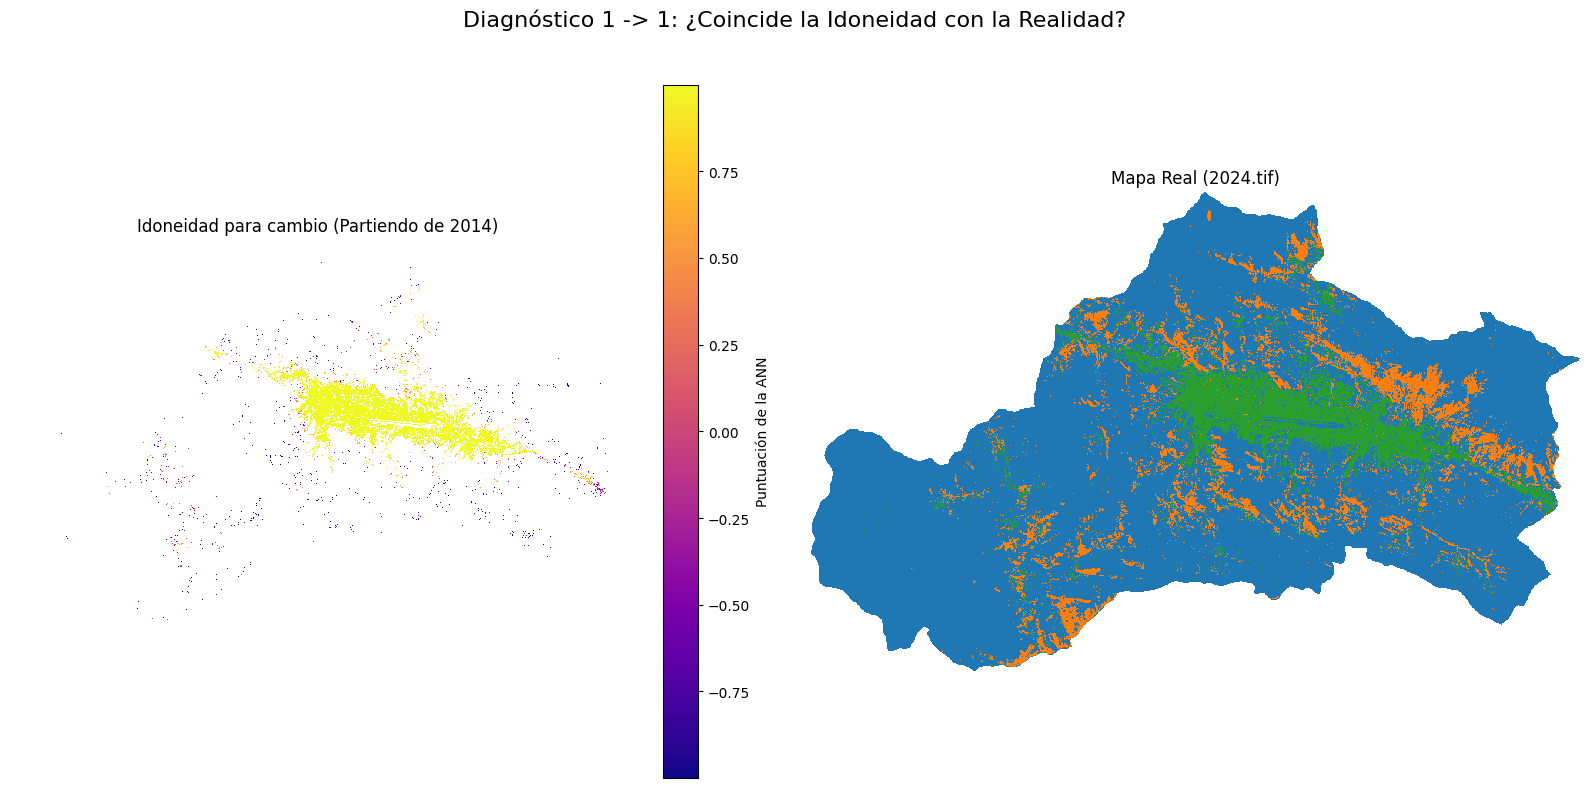

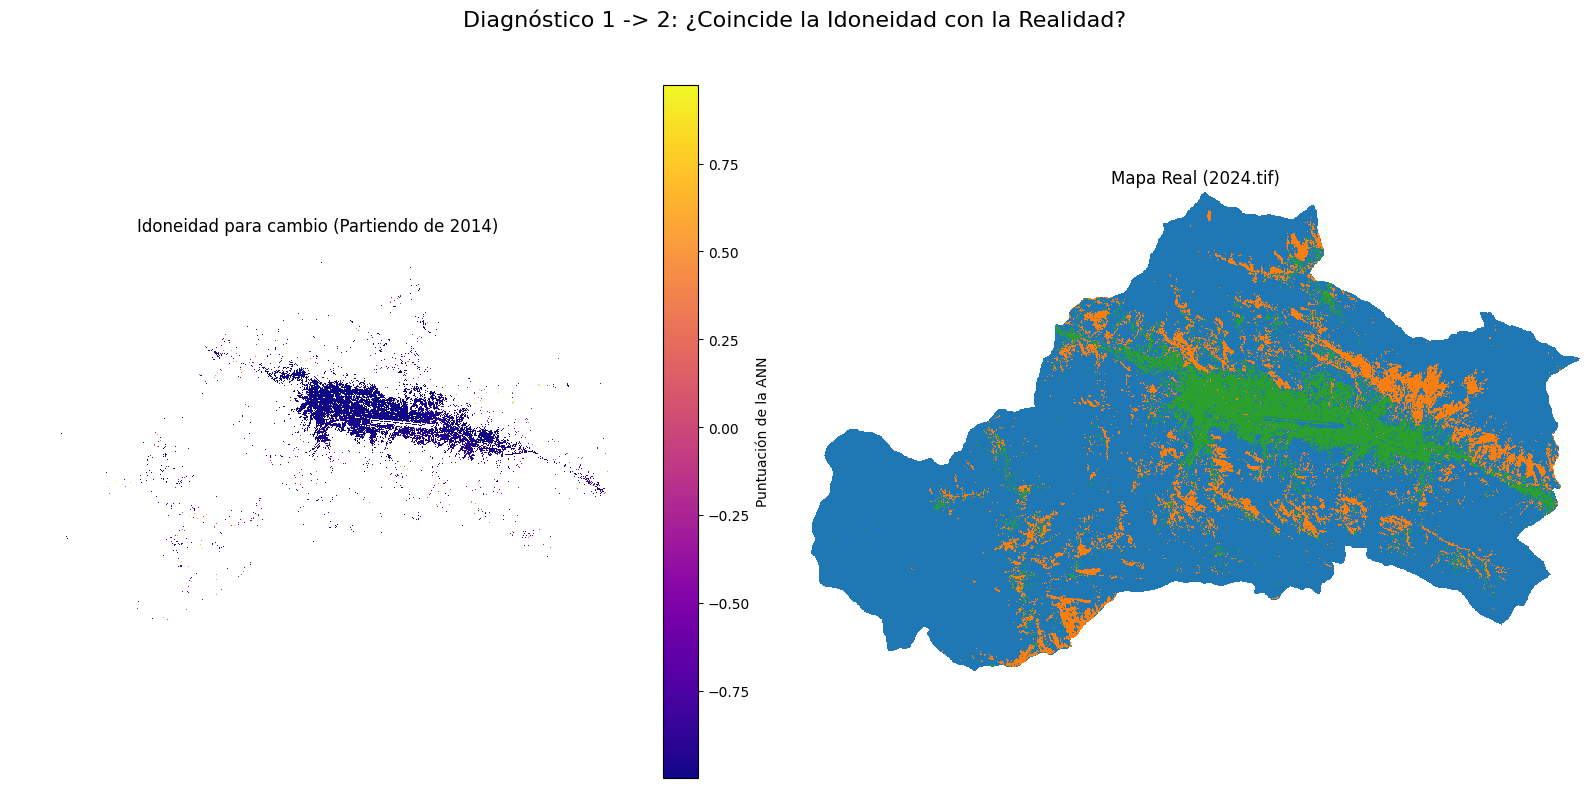

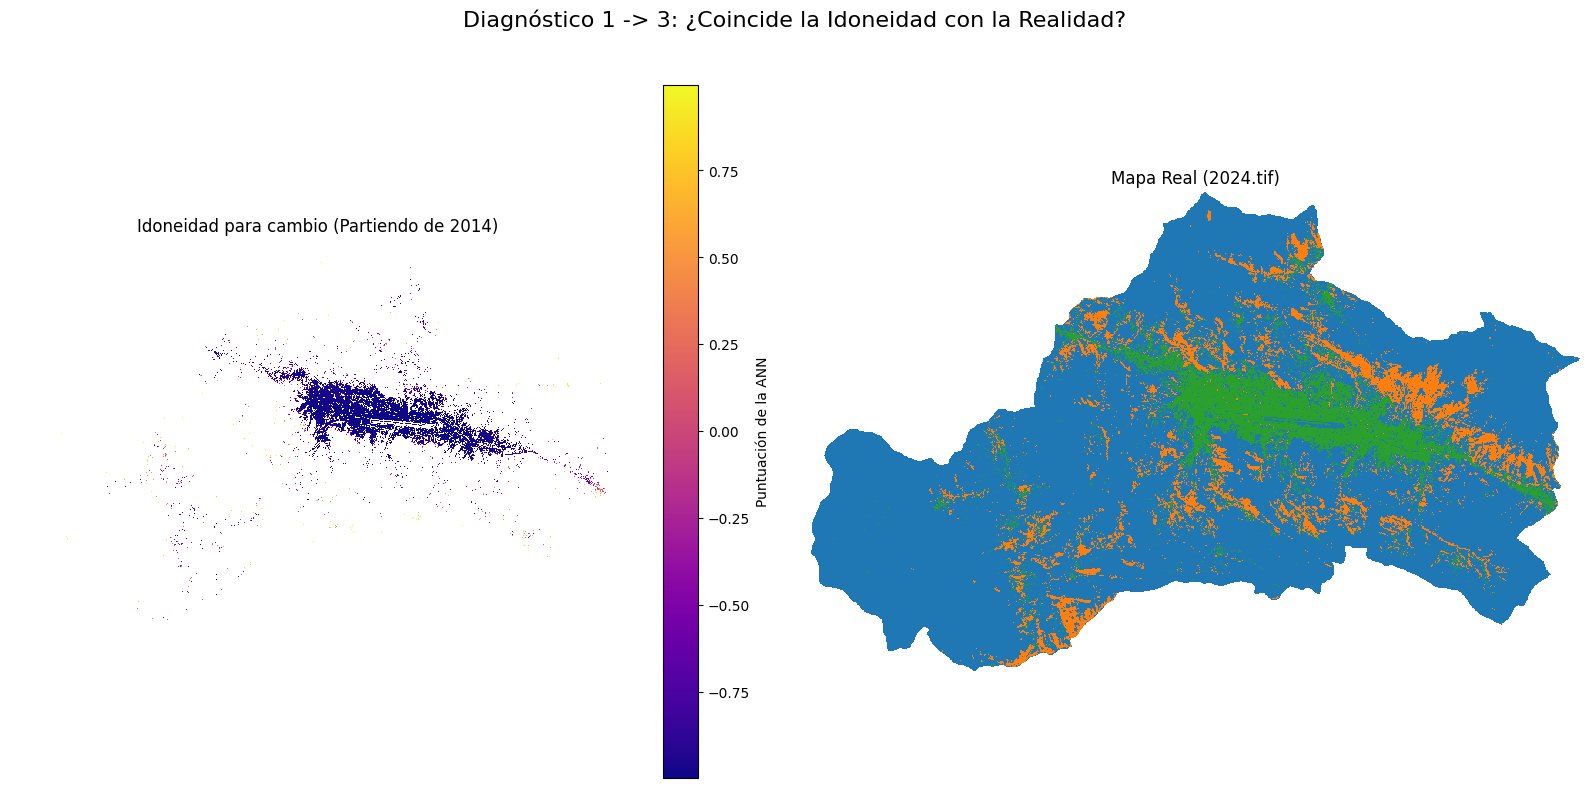

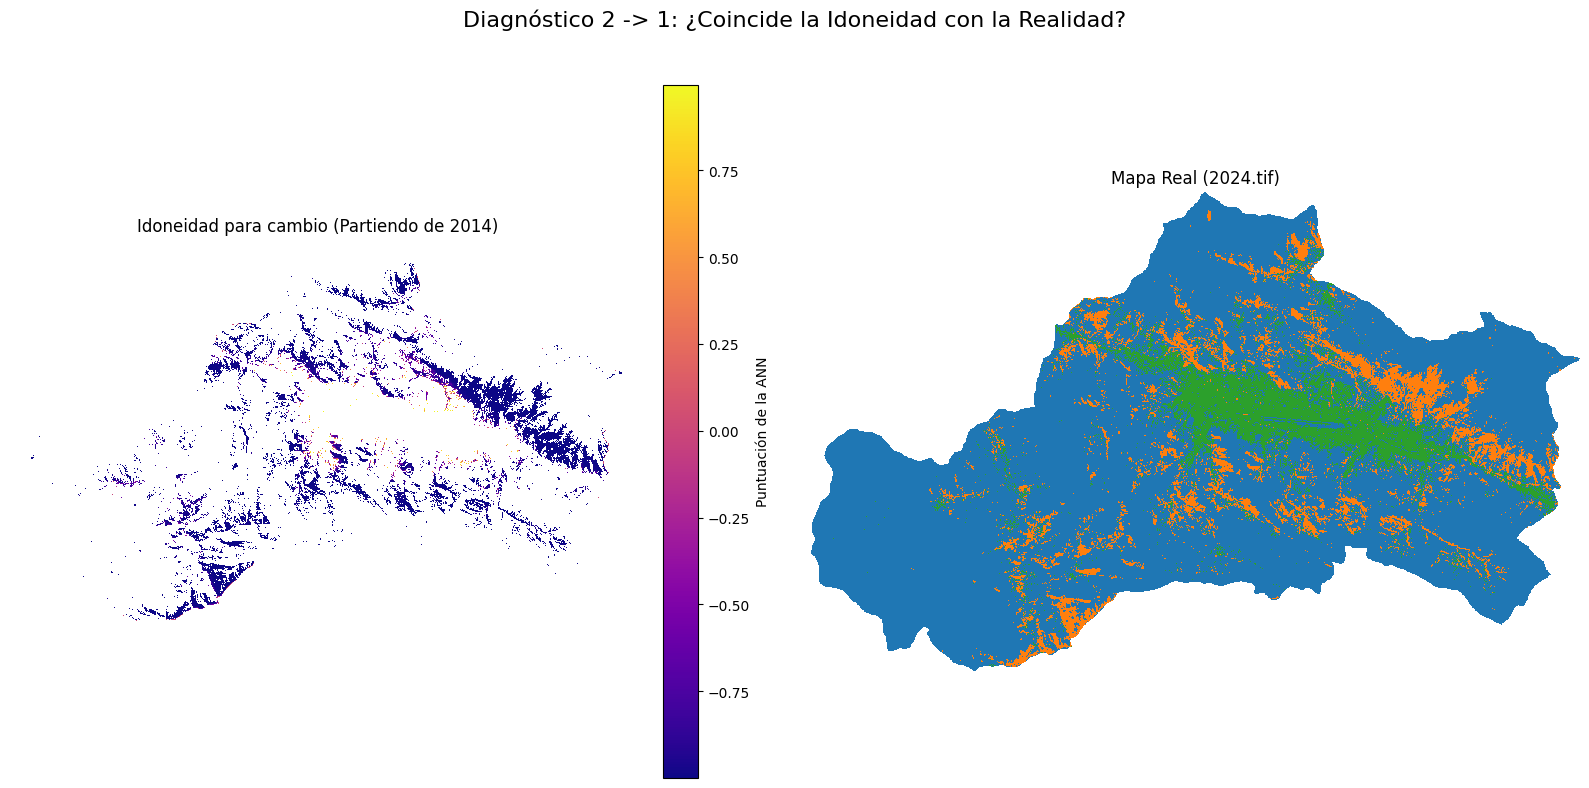

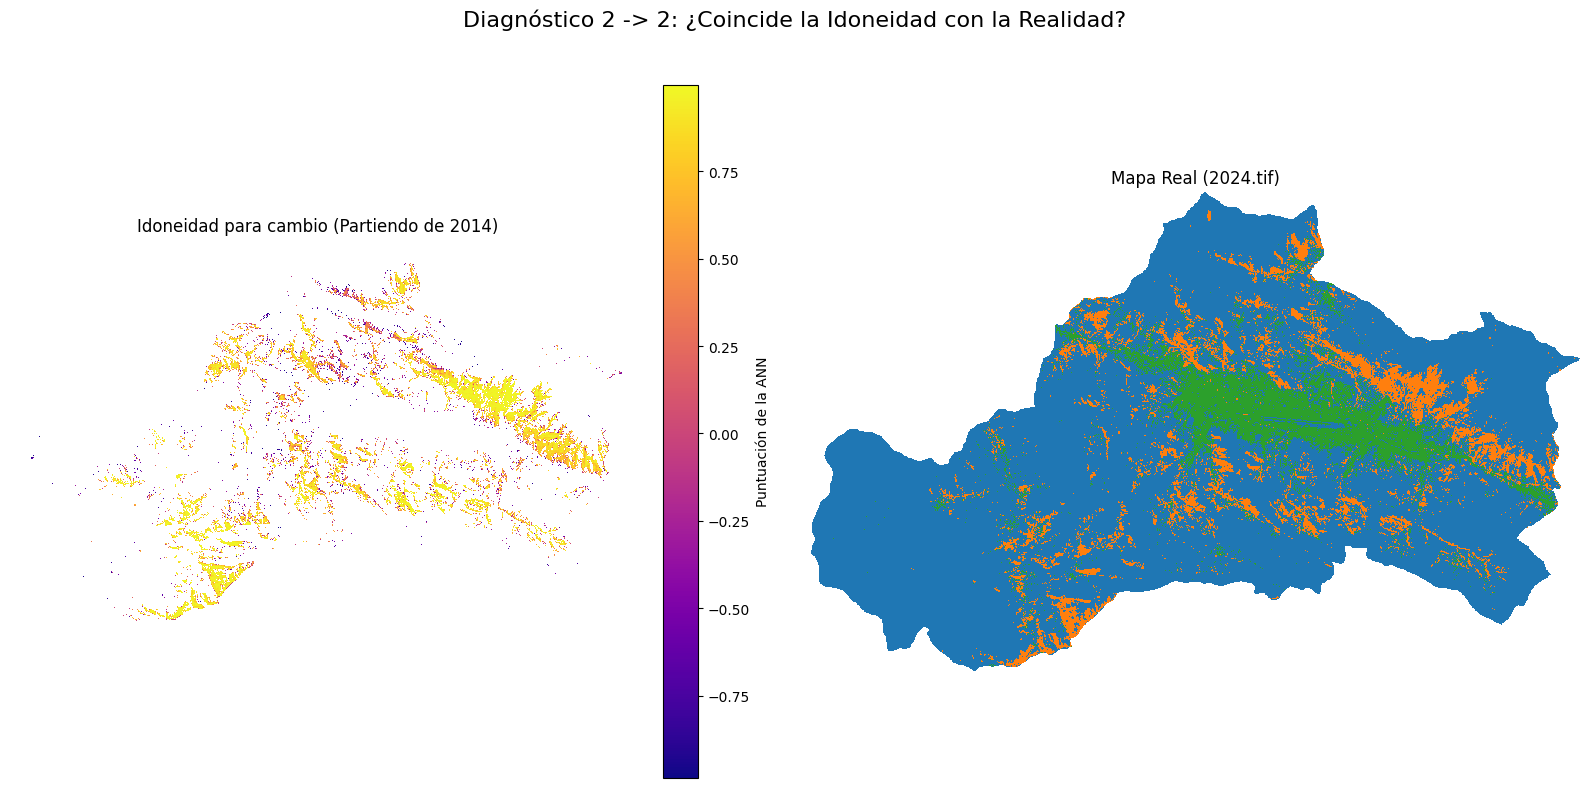

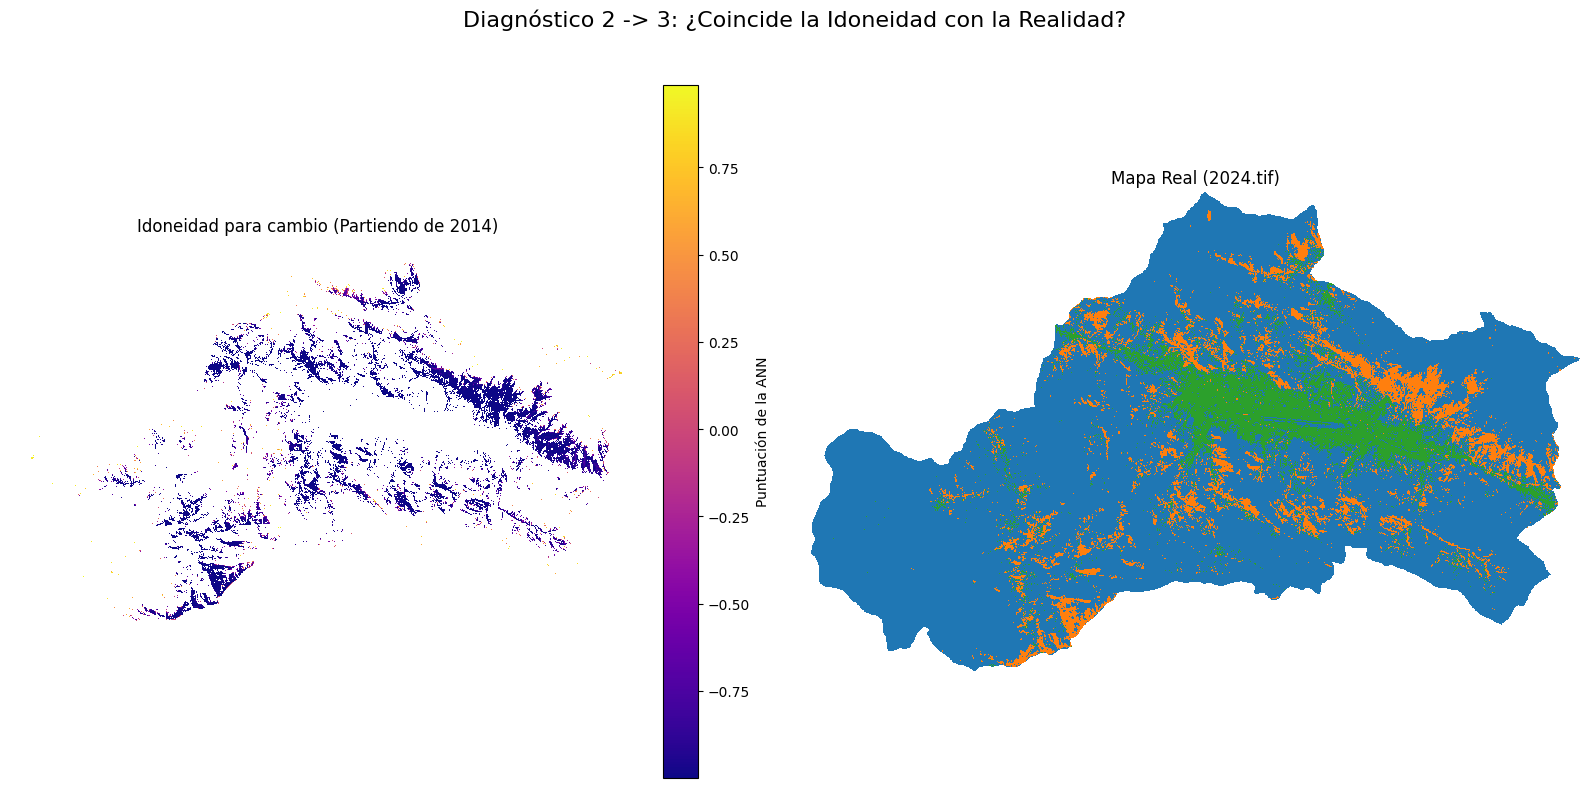

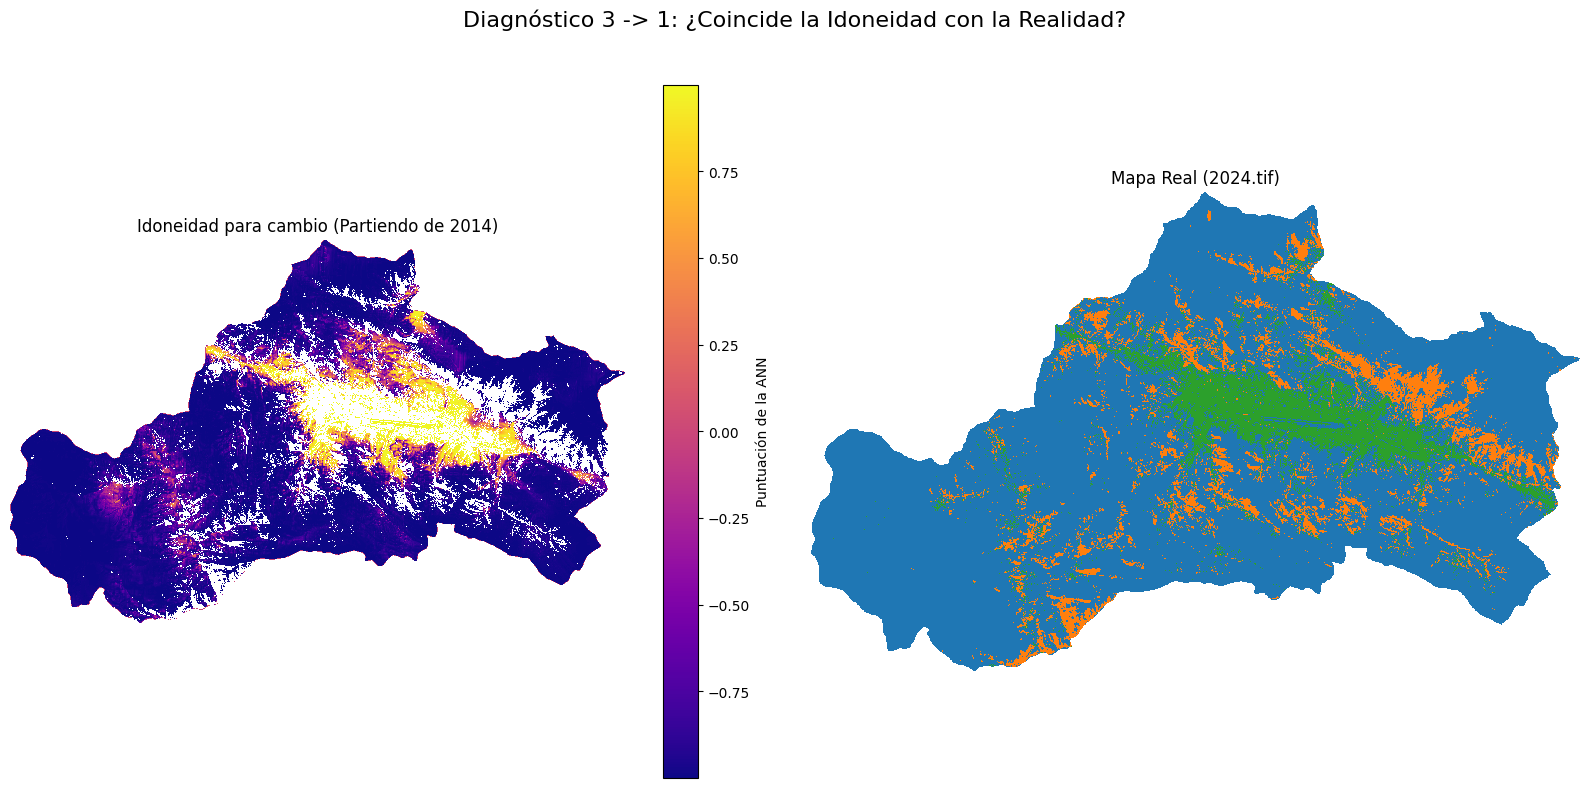

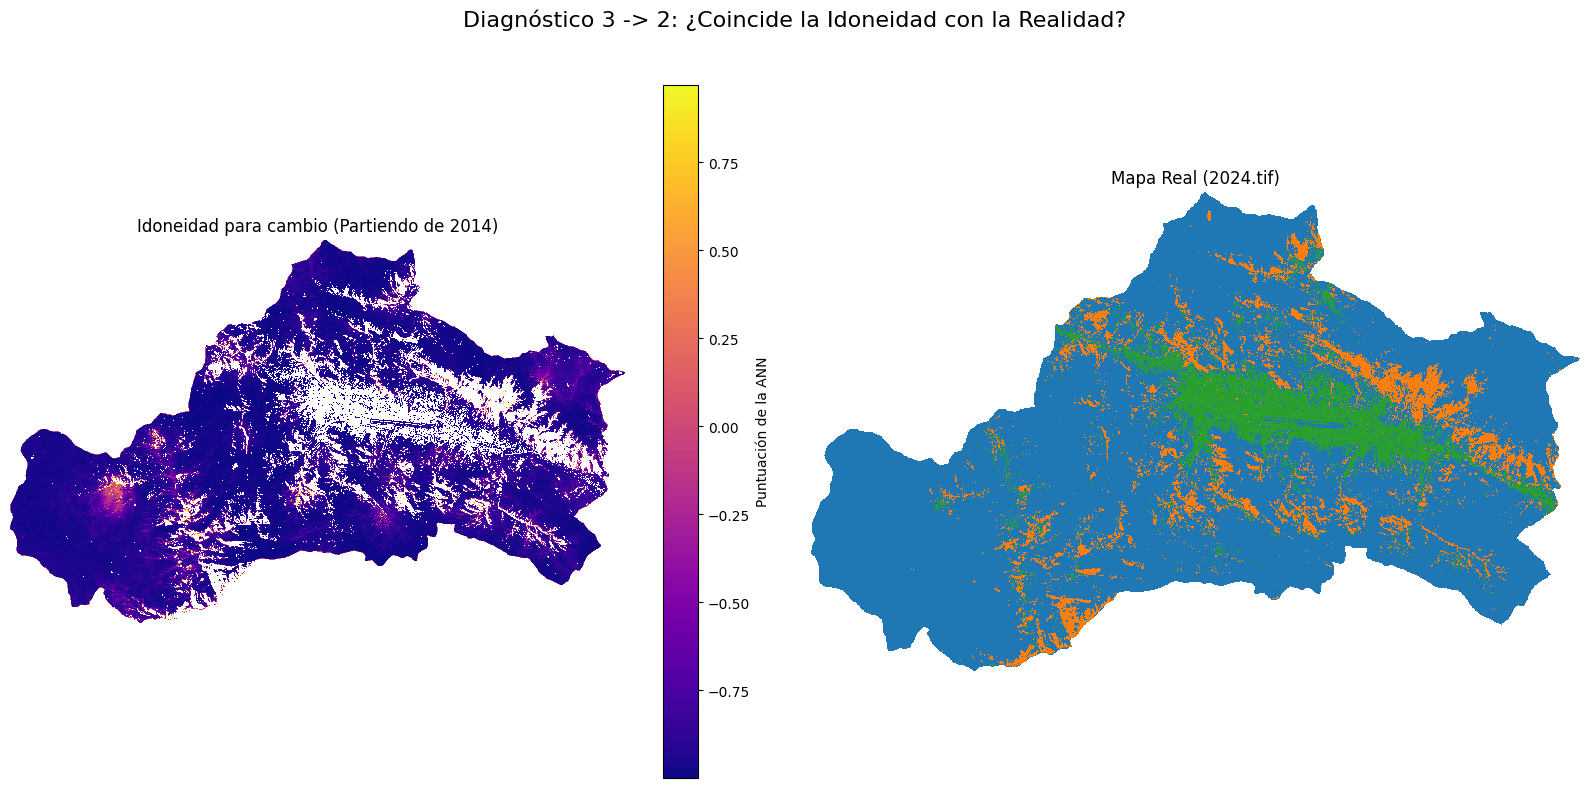

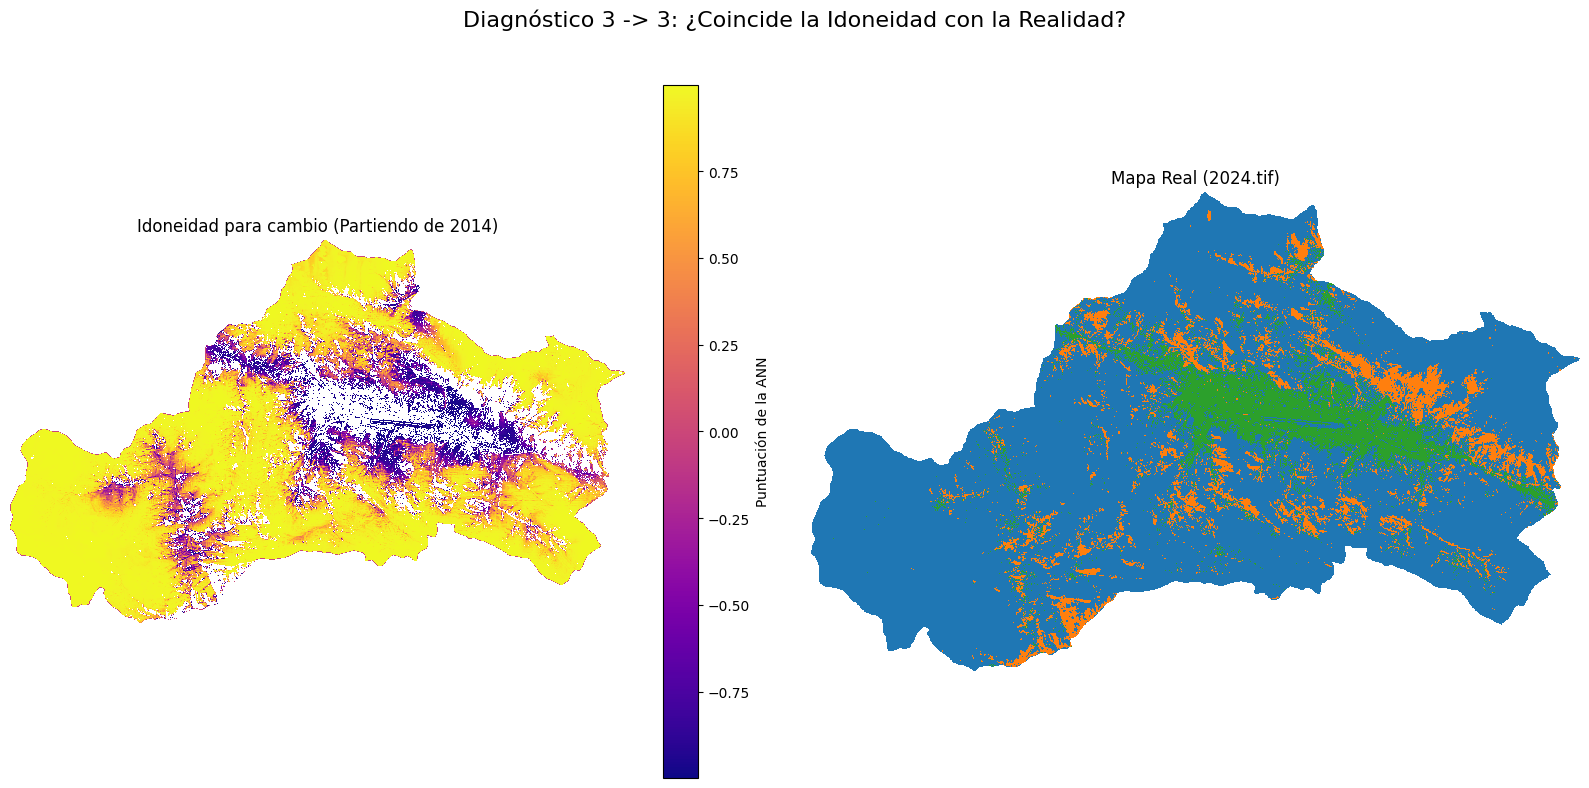

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import traceback

print("--- ANÁLISIS VISUAL DE LA VALIDACIÓN (2014 -> 2024) ---")

# Assuming variables 'clases' (o 'clases_lulc'), 'potential_maps_validacion',
# 'anho_2014_val', 'anho_2024_real', 'cmap_discreto', 'norm' y 'rutas'
# ya existsn de las celdas anteriores.

# Asegurarse de que 'clases' esté definido
if 'clases' not in locals() and 'clases_lulc' in locals():
     clases = clases_lulc

# Bucle sobre todas las clases de origen
for clase_origen_a_inspeccionar in clases:
    # Bucle sobre todas las clases de destino
    for clase_destino_a_inspeccionar in clases:

        print(f"\n====================================================")
        print(f"DIAGNÓSTICO (VALIDACIÓN): {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}")
        print(f"====================================================")

        try:
            # 1. Preparar el mapa de idoneidad para la transición seleccionada
            print(f"Generando mapa de idoneidad para la transición {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}...")

            mapa_de_potencial = potential_maps_validacion[clase_destino_a_inspeccionar]

            # --- !! CORRECCIÓN LÓGICA IMPORTANTE !! ---
            # El mapa de partida para la VALIDACIÓN (2014->2024) es el de 2014.
            mapa_de_partida_array = anho_2014_val.getBand(1)

            candidate_pixels_mask = (mapa_de_partida_array.data == clase_origen_a_inspeccionar)

            suitability_map = mapa_de_potencial * candidate_pixels_mask

            # --- INICIO DE LA MODIFICACIÓN VISUAL (LO QUE PIDES) ---
            # Convertir a float para poder usar np.nan
            suitability_map_float = suitability_map.astype(float)

            # 1. Ocultar los píxeles que NO son candidatos (donde la máscara es False)
            suitability_map_float[~candidate_pixels_mask] = np.nan

            # 2. Ocultar los píxeles que son NoData en el mapa original
            suitability_map_float[mapa_de_partida_array.mask] = np.nan
            # --- FIN DE LA MODIFICACIÓN VISUAL ---

            # 2. Cargar el mapa real de 2024 (el mapa de 'realidad' para comparar)
            # (Assuming that se llama 'anho_2024_real' de la celda de validación)
            real_2024_data = anho_2024_real.getBand(1)

            # --- GRÁFICO: Idoneidad vs. Mapa Real 2024 ---
            print("Mostrando Gráfico: Idoneidad vs. Realidad")
            fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
            fig1.suptitle(f'Diagnóstico {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}: ¿Coincide la Idoneidad con la Realidad?', fontsize=16)

            # Gráfico 1a: Mapa de Idoneidad (Ahora usa suitability_map_float)
            im1 = ax1.imshow(suitability_map_float, cmap='plasma', interpolation='nearest')
            ax1.set_title(f'Idoneidad para cambio (Partiendo de 2014)')
            ax1.axis('off')
            fig1.colorbar(im1, ax=ax1, label='Puntuación de la ANN')

            # Gráfico 1b: Mapa Real 2024
            ax2.imshow(real_2024_data, cmap=cmap_discreto, norm=norm, interpolation='nearest')
            ax2.set_title(f'Mapa Real ({os.path.basename(rutas["anho_2024"])})')
            ax2.axis('off')

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show() # Muestra el gráfico y pasa a la siguiente iteración.

        except KeyError as e:
            print(f"\n!!!!! ERROR: La clave {e} no se encontró en el diccionario 'potential_maps_validacion'.")
        except NameError as e:
            print(f"\n!!!!! ERROR DE VARIABLE: {e}. Asegúrate de que 'anho_2014_val' y 'anho_2024_real' existan.")
        except Exception as e:
            print(f"\n!!!!!! OCURRIÓ UN ERROR DURANTE LA VISUALIZACIÓN DE DIAGNÓSTICO !!!!!!")
            traceback.print_exc()

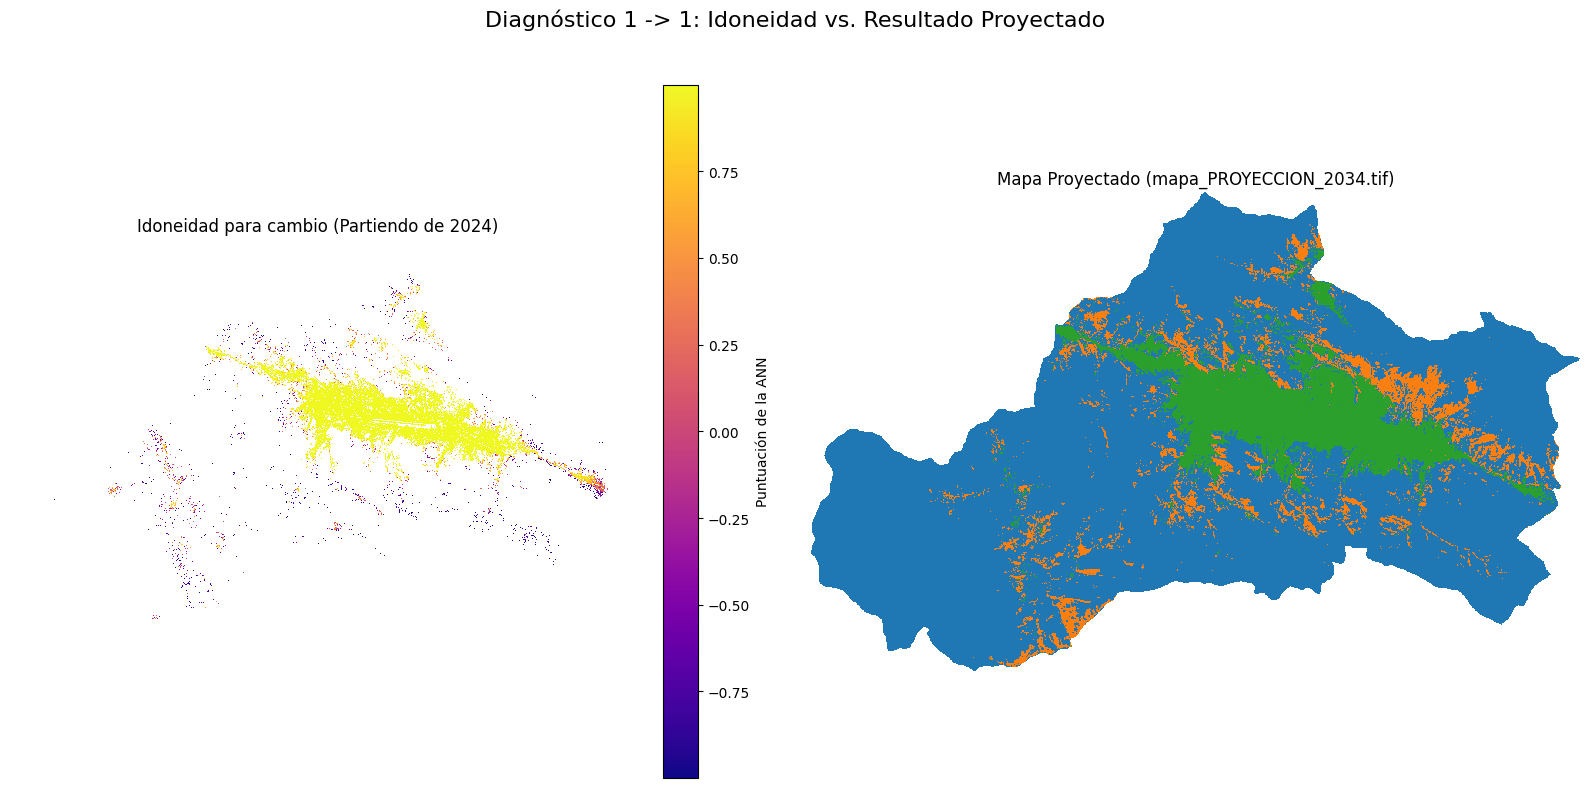

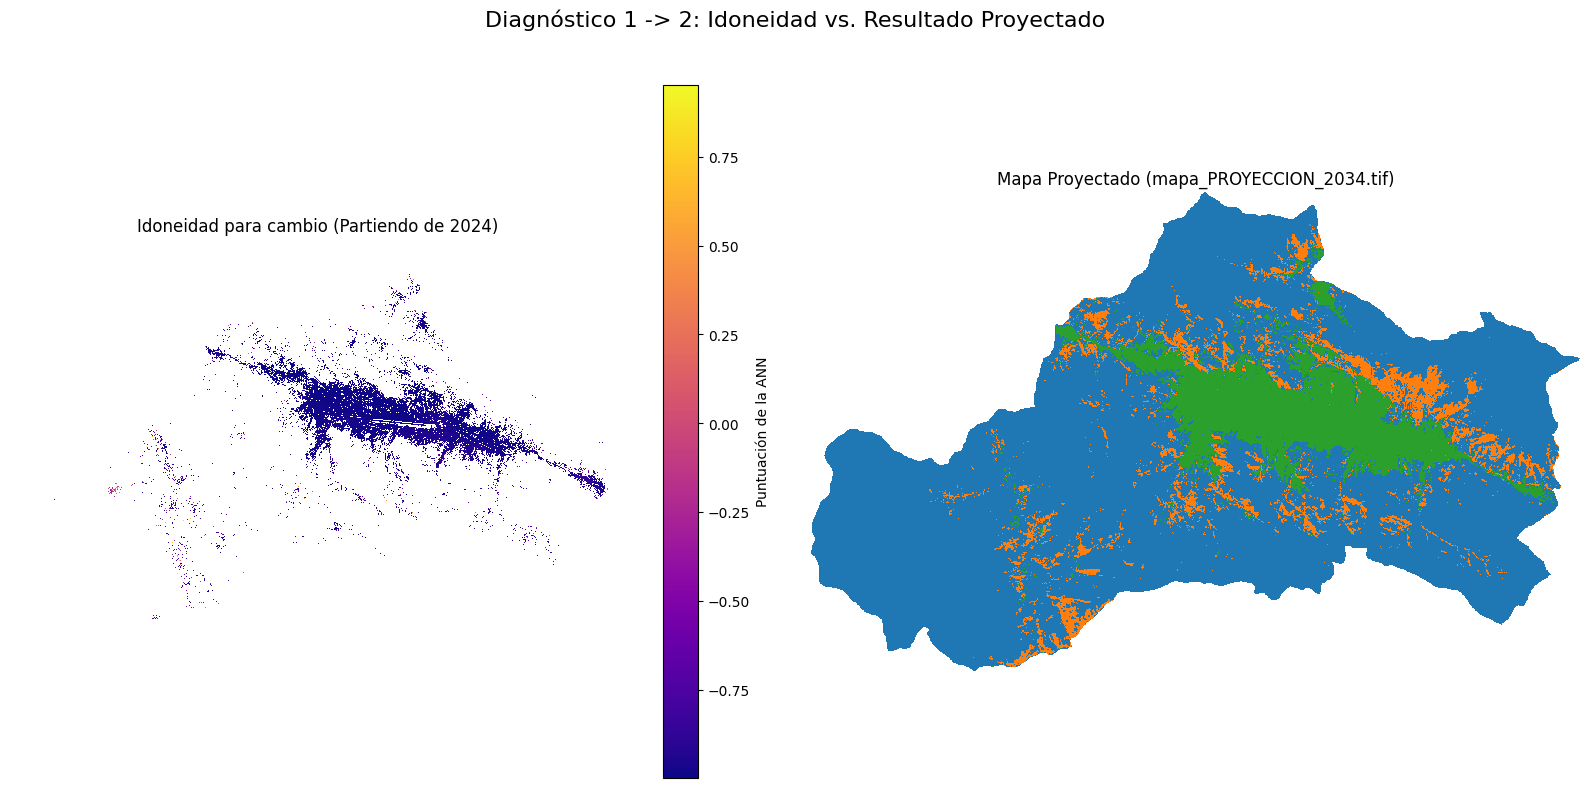

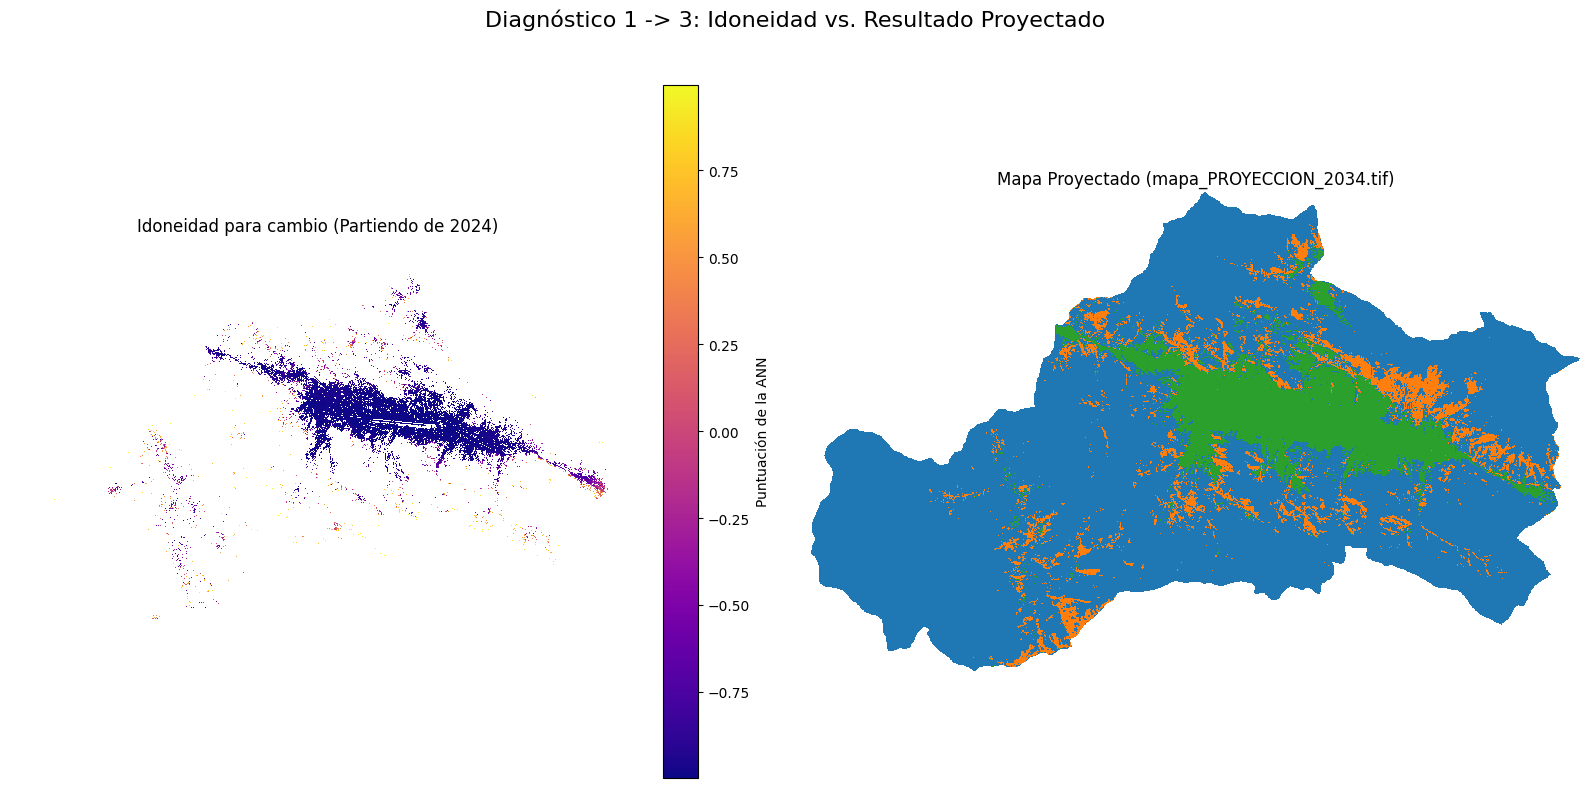

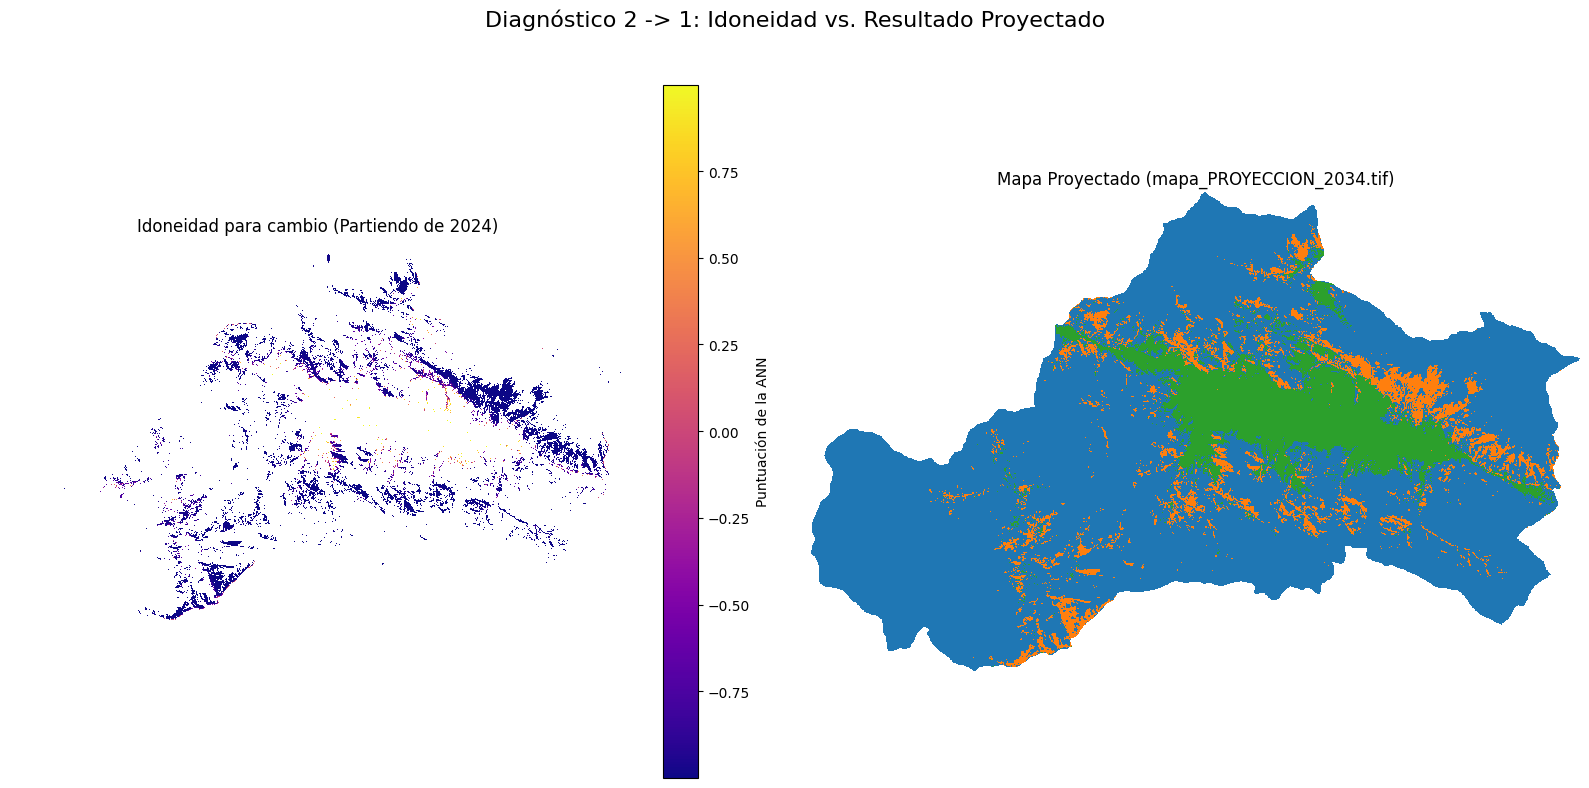

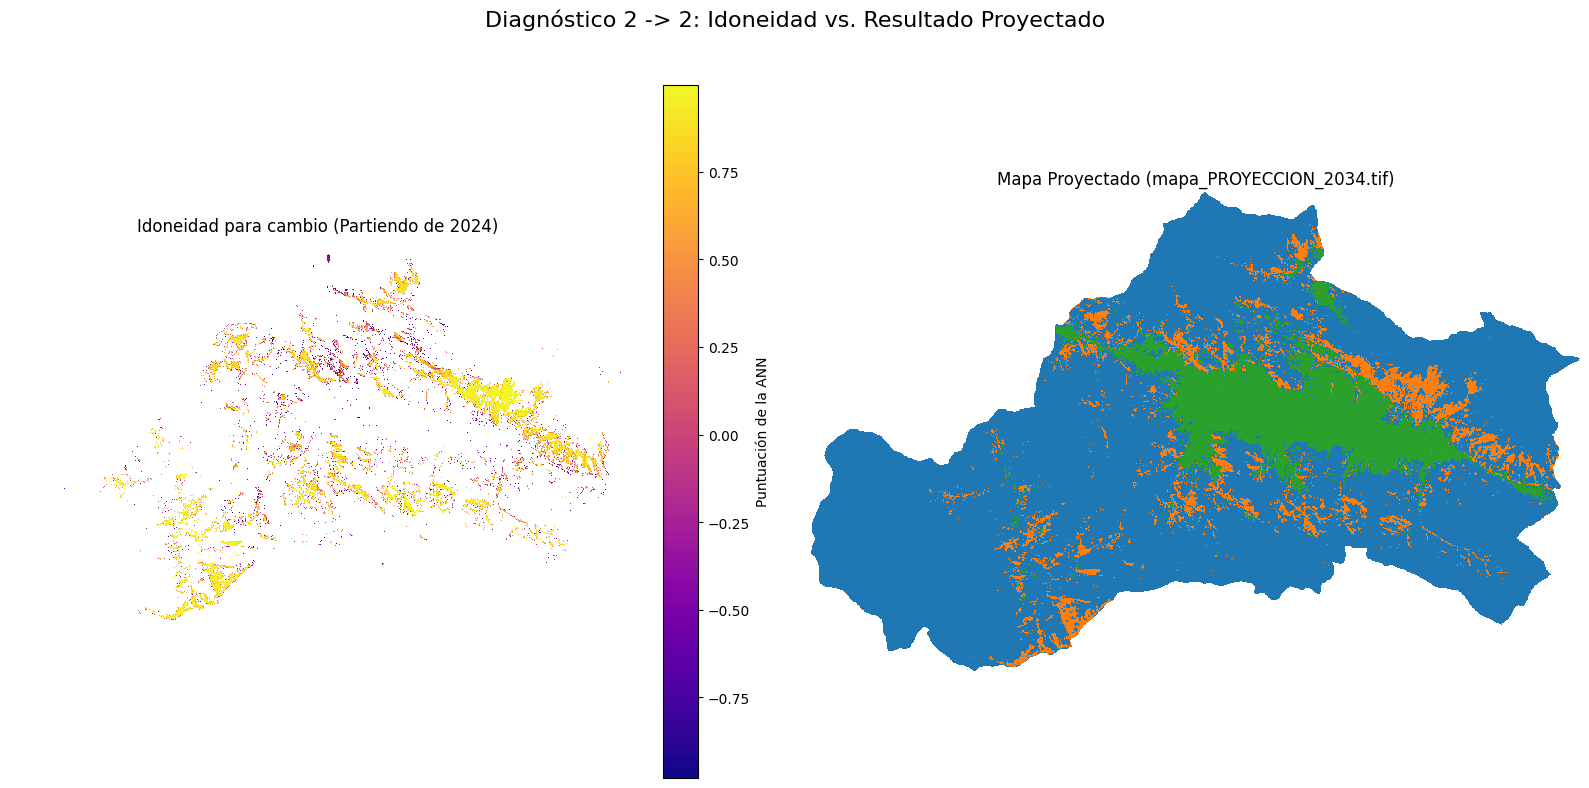

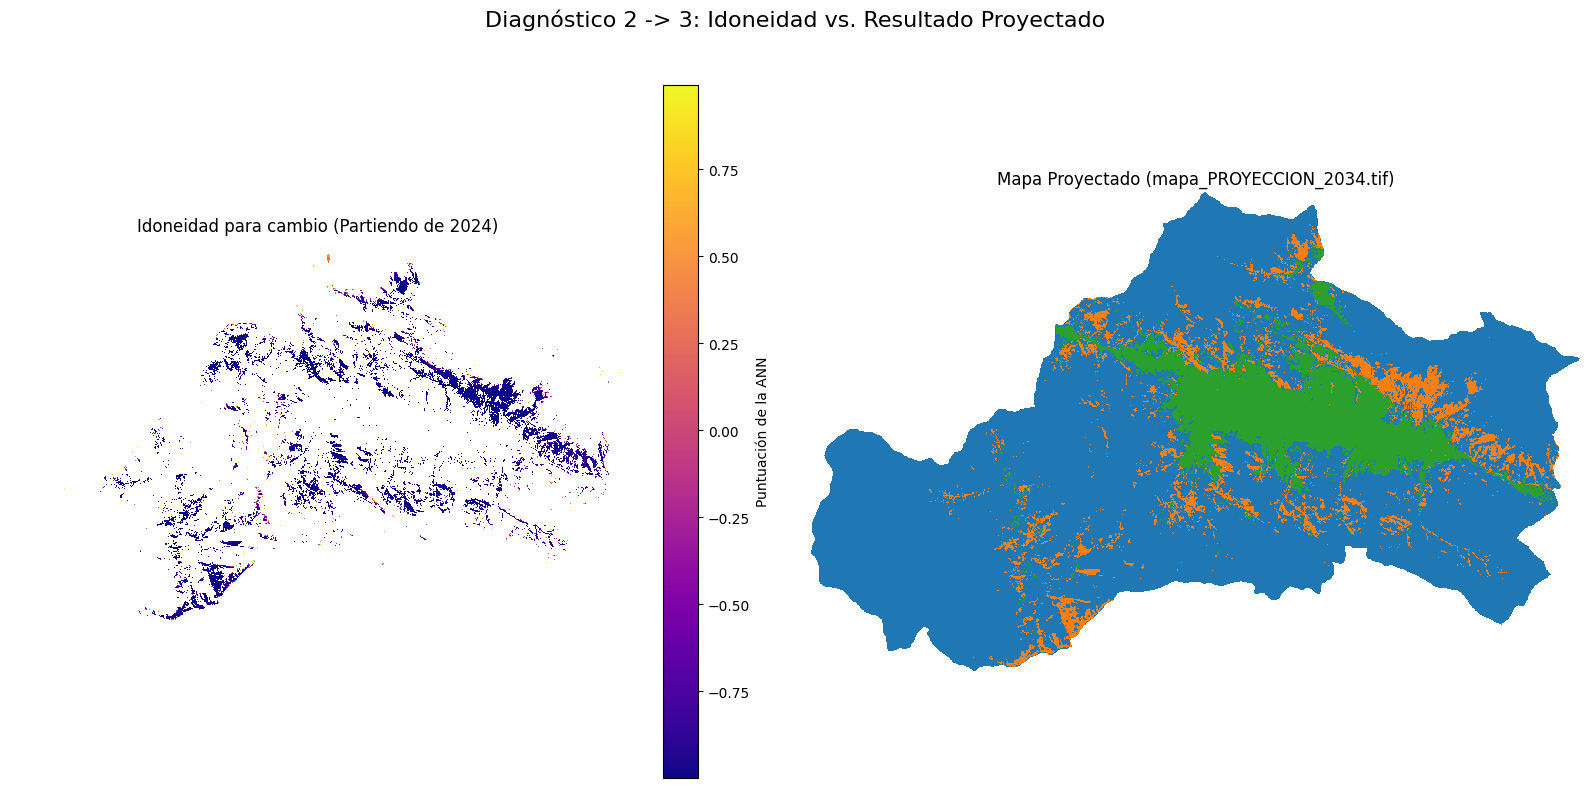

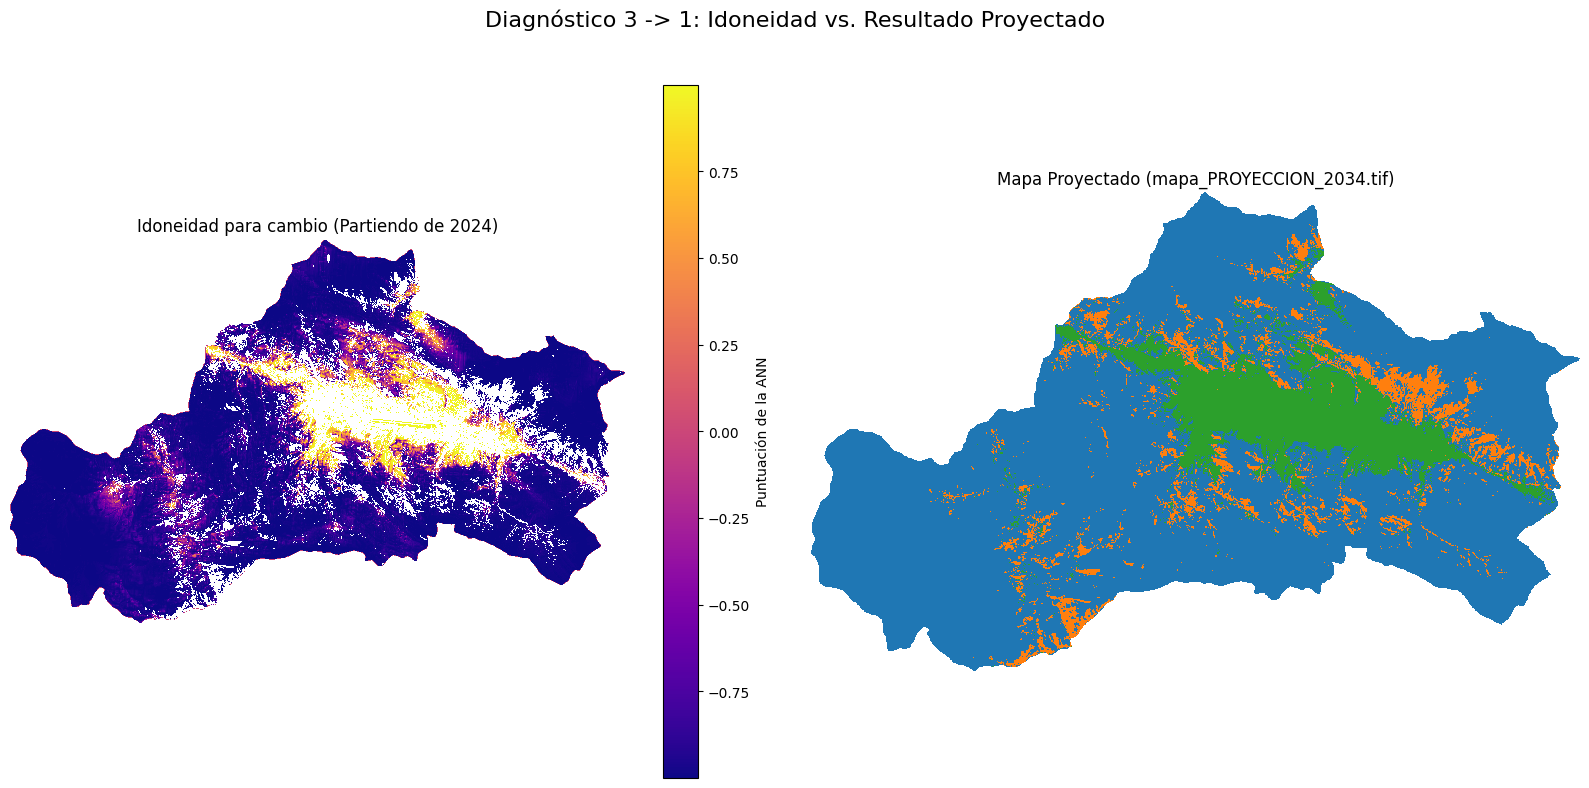

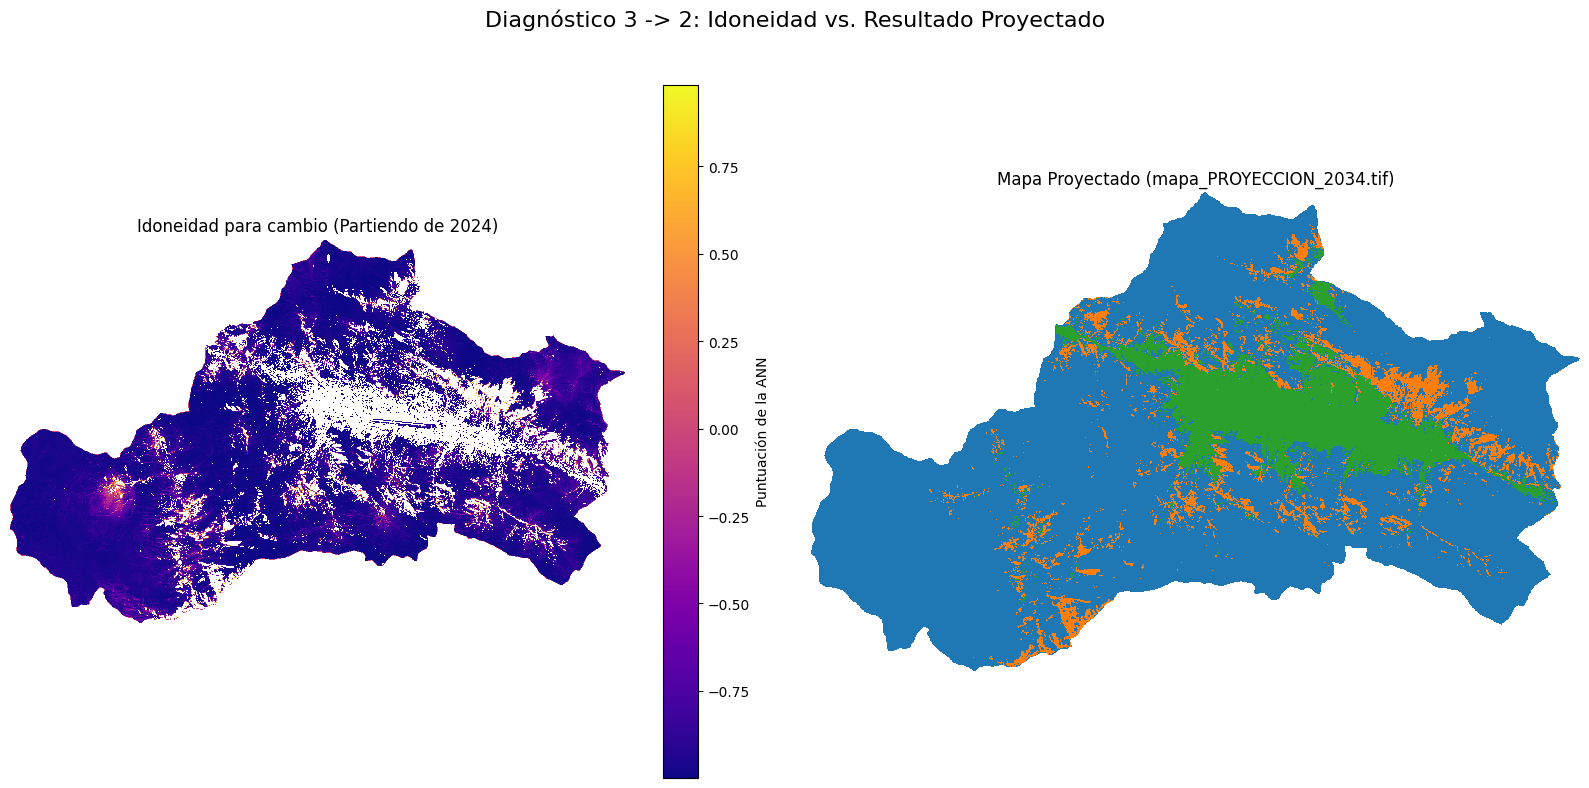

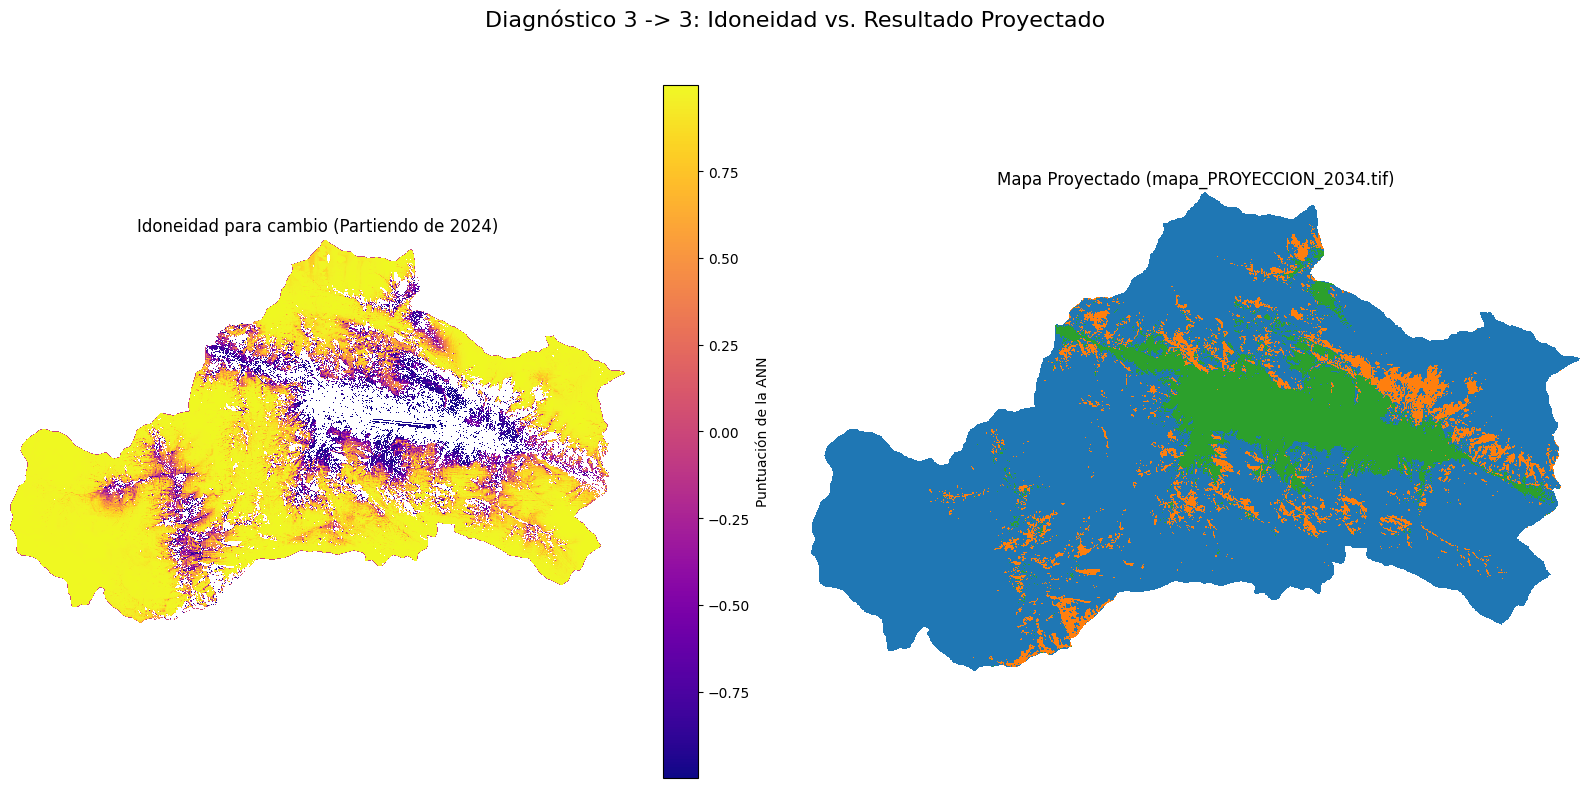

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

print("--- ANÁLISIS VISUAL DE LA PROYECCIÓN (2024 -> 2034) ---")

# Assuming that 'clases_lulc', 'potential_maps_proyeccion', 'anho_2024_proy',
# 'predicted_raster_proyeccion', 'cmap_discreto', y 'norm' existsn de la celda anterior.

# Bucle sobre todas las clases de origen
for clase_origen_a_inspeccionar in clases_lulc:
    # Bucle sobre todas las clases de destino
    for clase_destino_a_inspeccionar in clases_lulc:

        print(f"\n====================================================")
        print(f"DIAGNÓSTICO (PROYECCIÓN): {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}")
        print(f"====================================================")

        try:
            # 1. Preparar el mapa de idoneidad de la proyección
            mapa_de_potencial = potential_maps_proyeccion[clase_destino_a_inspeccionar]

            # El mapa de partida es el del inicio del período de proyección (2024)
            mapa_de_partida_array = anho_2024_proy.getBand(1)

            candidate_pixels_mask = (mapa_de_partida_array.data == clase_origen_a_inspeccionar)

            suitability_map = mapa_de_potencial * candidate_pixels_mask

            # Convertir a float para usar np.nan
            suitability_map_float = suitability_map.astype(float)
            suitability_map_float[~candidate_pixels_mask] = np.nan # Ocultar no-candidatos
            suitability_map_float[mapa_de_partida_array.mask] = np.nan # Ocultar NoData original

            # 2. Cargar el mapa PROYECTADO de 2034
            projected_2034_data = predicted_raster_proyeccion.getBand(1)

            # --- GRÁFICO: Idoneidad vs. Mapa Proyectado 2034 ---
            print("Mostrando Gráfico: Idoneidad vs. Proyección")
            fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
            fig1.suptitle(f'Diagnóstico {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}: Idoneidad vs. Resultado Proyectado', fontsize=16)

            # Gráfico 1a: Mapa de Idoneidad
            im1 = ax1.imshow(suitability_map_float, cmap='plasma', interpolation='nearest')
            ax1.set_title(f'Idoneidad para cambio (Partiendo de 2024)')
            ax1.axis('off')
            fig1.colorbar(im1, ax=ax1, label='Puntuación de la ANN')

            # Gráfico 1b: Mapa Proyectado 2034
            ax2.imshow(projected_2034_data, cmap=cmap_discreto, norm=norm, interpolation='nearest')
            ax2.set_title(f'Mapa Proyectado ({os.path.basename(rutas["salida_proyeccion"])})')
            ax2.axis('off')

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show()

        except KeyError as e:
            print(f"\n!!!!! ERROR: La clave {e} no se encontró en 'potential_maps_proyeccion'.")
        except Exception as e:
            print(f"\n!!!!!! OCURRIÓ UN ERROR DURANTE LA VISUALIZACIÓN DE DIAGNÓSTICO !!!!!!")
            traceback.print_exc()